In [1]:
#import speckle
import numpy as np
import numpy.ma as ma
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.gridspec as gridspec
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter


%matplotlib inline

In [2]:
import pyCHX

In [3]:
from pyCHX.chx_packages import *
import pickle as cpk
from pyCHX.chx_xpcs_xsvs_jupyter_V1 import *


/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/databroker/v1.py:75: UserWarning: In databroker 2.x, there are separate notions of 'server' and 'client', and register_handler(...) has no effect on the client. Likely this is being done for you on the server side, so you should not worry about this message unless you encounter trouble loading large array data.
  warnings.warn(
/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/pyCHX/chx_generic_functions.py:827: SyntaxWarning: invalid escape sequence '\m'
  text_string = "%s $\mu$m" % scalebar_size
/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/pyCHX/chx_correlationc.py:893: SyntaxWarning: invalid escape sequence '\i'
  g_2(q, \\tau) = \\beta_1[g_1(q, \\tau)]^{2} + g_\infty


Olog Password (username = asingh5): ········


/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/pyCHX/chx_specklecp.py:1557: SyntaxWarning: invalid escape sequence '\G'
  P(K) =(\frac{M}{<K>})^M \frac{K^(M-1)}{\Gamma(M)}\exp(-M\frac{K}{<K>})
/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/pyCHX/chx_specklecp.py:1634: SyntaxWarning: invalid escape sequence '\e'
  P(K) = \frac{<K>^K}{K!}\exp(-<K>)


In [4]:
from pyCHX.chx_generic_functions import RemoveHot,create_multi_rotated_rectangle_mask

In [5]:
import os, sys, imp, logging

import skbeam
#import skbeam.core.roi as skroi
import skbeam.core.correlation as corr
import skbeam.core.utils as utils
import skbeam.core.speckle as speckle

ModuleNotFoundError: No module named 'imp'

## Import scan

In [6]:
pwd

'/nsls2/users/asingh5'

In [7]:
#hdr.table()

In [7]:
uid = 188990 #dcm scan                #157379
hdr = db[uid]
detector = get_detector(db[uid])
#imgs = db.get_images(hdr, detector)
imgs = db.get_images(hdr, detector)

## Plot detector images

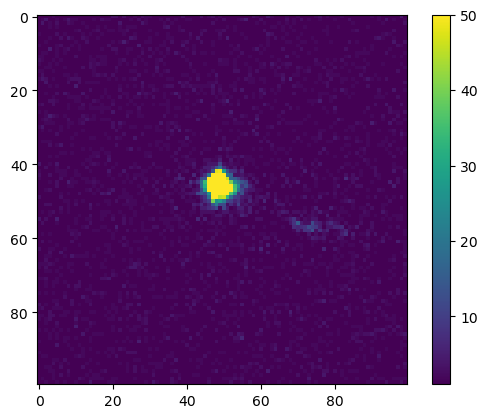

In [8]:
Iframes = np.array(imgs[0])[:,610:710, 240:340]
plt.imshow(Iframes[200], vmin=1, vmax = 50)
plt.colorbar()

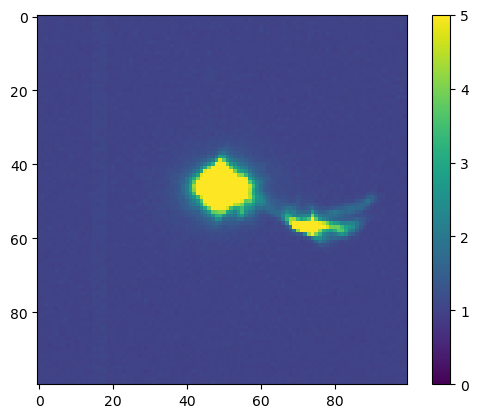

In [10]:
#plt.imshow(Iframes[0:100].mean(0),vmax = 50)
Iframes = np.array(imgs[0])[:,610:710, 240:340]
plt.imshow(Iframes.mean(0), vmin=0, vmax = 5)
#plt.imshow(np.nanmean(Iframes, axis = 0), vmax = 5)
plt.colorbar()

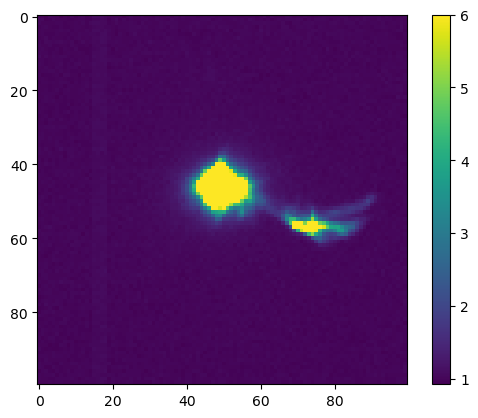

In [11]:
plt.imshow(np.nanmean(Iframes, axis = 0), vmax = 6)
plt.colorbar()

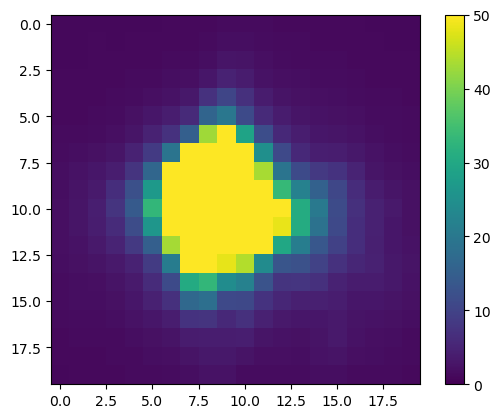

In [12]:
Int = np.array(Iframes[1:2000,36:56,40:60])
plt.imshow(np.nanmean(Int, axis = 0), vmin=0, vmax = 50)
plt.colorbar()

In [13]:
Iframes_avg_gf = gaussian_filter(Int.mean(0),1)

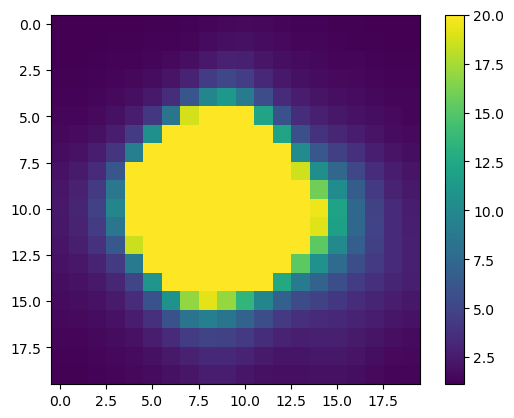

In [14]:
plt.imshow(Iframes_avg_gf, vmax = 20)
plt.colorbar()

In [15]:
Iframes_avg_sg = savgol_filter(Int.mean(0),11,7)

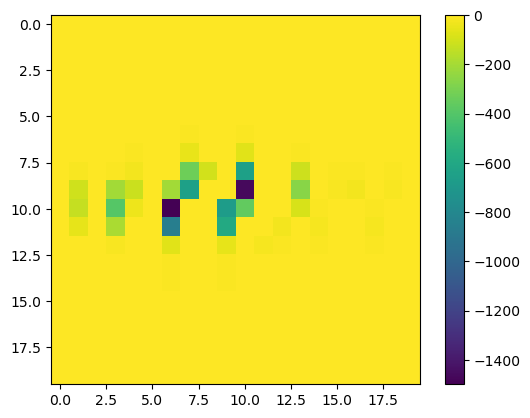

In [16]:
Isub = Int.mean(0)-Iframes_avg_sg
plt.imshow(Isub, vmax = 2.0)
plt.colorbar()

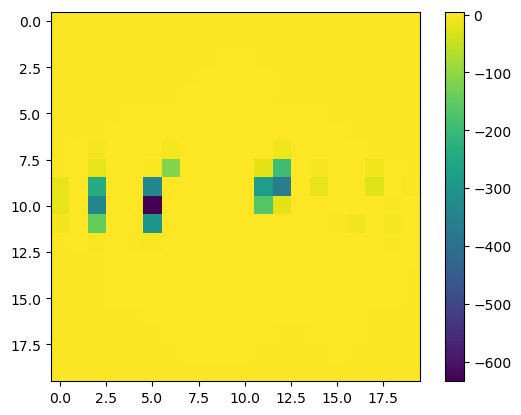

In [16]:
plt.imshow(Iframes_avg_sg, vmax = 5)
plt.colorbar()

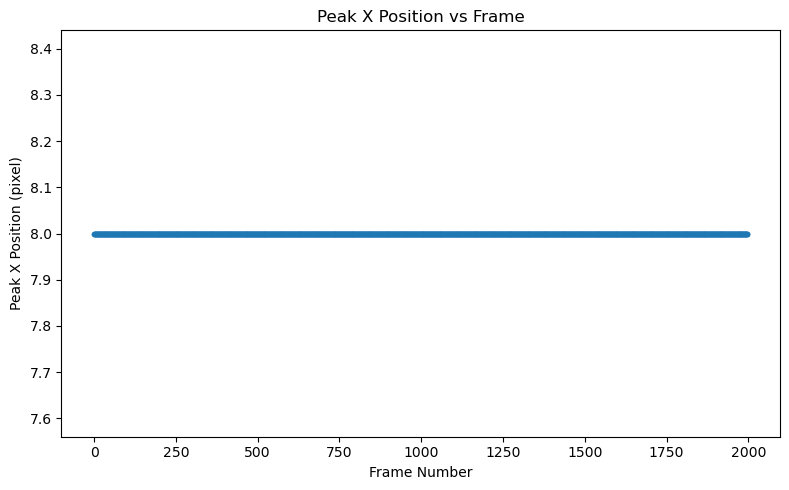

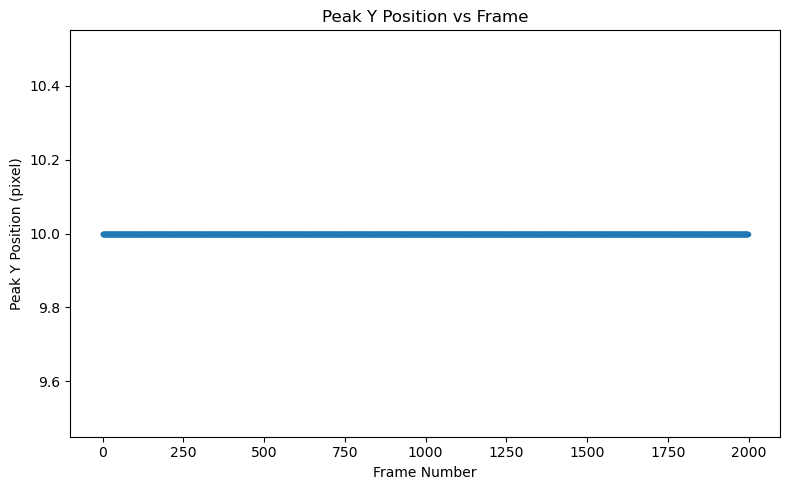

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Assumptions
# ----------------------------------------------------------
# Int.shape = (nFrames, Ny, Nx)
# ==========================================================

# ----------------------------------------------------------
# Number of frames
# ----------------------------------------------------------
n_frames = 1998

# ----------------------------------------------------------
# ROI around the peak
# Change according to your peak location
# ----------------------------------------------------------
x_min, x_max = 0, 20
y_min, y_max = 0, 20

# ----------------------------------------------------------
# Arrays to store peak positions
# ----------------------------------------------------------
x_peak = []
y_peak = []

# ==========================================================
# Loop over frames
# ==========================================================
for i in range(n_frames):

    img = Int[i]

    # ------------------------------------------
    # ROI extraction
    # ------------------------------------------
    roi = img[y_min:y_max, x_min:x_max]

    # ------------------------------------------
    # 1D projections
    # ------------------------------------------
    x_profile = np.sum(roi, axis=0)
    y_profile = np.sum(roi, axis=1)

    # ------------------------------------------
    # Peak positions (maximum intensity)
    # ------------------------------------------
    x_pos = np.argmax(x_profile) + x_min
    y_pos = np.argmax(y_profile) + y_min

    # ------------------------------------------
    # Store positions
    # ------------------------------------------
    x_peak.append(x_pos)
    y_peak.append(y_pos)

# ==========================================================
# Convert to arrays
# ==========================================================
x_peak = np.array(x_peak)
y_peak = np.array(y_peak)

# ==========================================================
# Plot X position vs frame
# ==========================================================
plt.figure(figsize=(8,5))

plt.plot(np.arange(n_frames), x_peak, '.-')

plt.xlabel('Frame Number')
plt.ylabel('Peak X Position (pixel)')
plt.title('Peak X Position vs Frame')

plt.tight_layout()
plt.show()

# ==========================================================
# Plot Y position vs frame
# ==========================================================
plt.figure(figsize=(8,5))

plt.plot(np.arange(n_frames), y_peak, '.-')

plt.xlabel('Frame Number')
plt.ylabel('Peak Y Position (pixel)')
plt.title('Peak Y Position vs Frame')

plt.tight_layout()
plt.show()

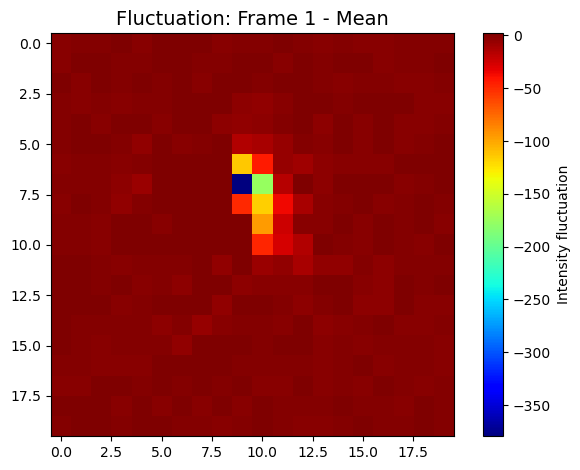

In [18]:
Ifluc = Int[230] - np.mean(Int, axis=0)

plt.imshow(Ifluc, vmax=2.0, cmap='jet')
plt.colorbar(label='Intensity fluctuation')

plt.title("Fluctuation: Frame 1 - Mean", fontsize=14)
plt.tight_layout()
plt.show()

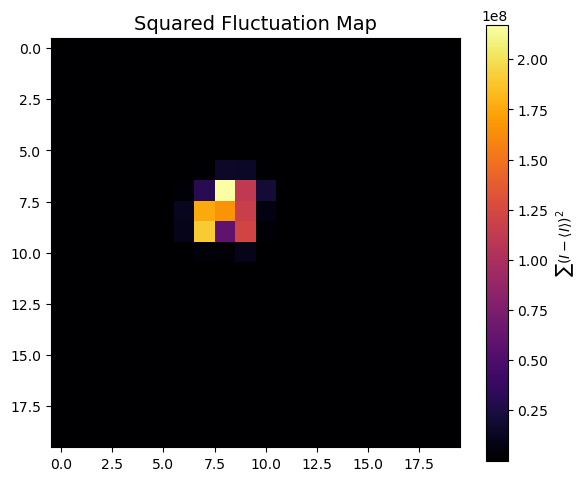

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Select frames
# -------------------------
Int_subset = Int[:1999]

# -------------------------
# Compute mean image
# -------------------------
I_mean = np.mean(Int_subset, axis=0)

# -------------------------
# Compute squared fluctuation sum
# -------------------------
Ifluc_sq = np.sum((Int_subset - I_mean)**2, axis=0)

# -------------------------
# Plot (linear scale)
# -------------------------
plt.figure(figsize=(6,5))

plt.imshow(Ifluc_sq, cmap='inferno')
plt.colorbar(label=r'$\sum (I - \langle I \rangle)^2$')

plt.title("Squared Fluctuation Map", fontsize=14)

plt.tight_layout()
plt.show()

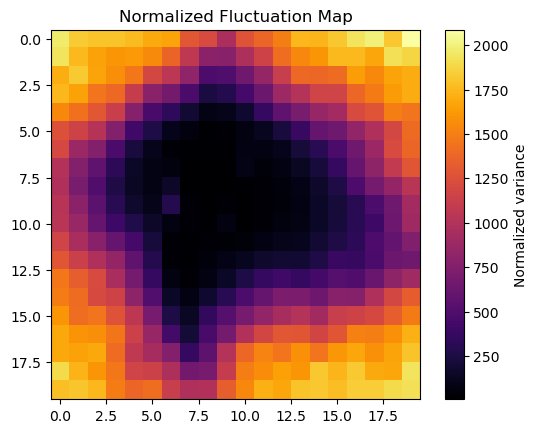

In [25]:
variance_map = Ifluc_sq / (I_mean**2 + 1e-10)

plt.imshow(variance_map, cmap='inferno')
plt.colorbar(label='Normalized variance')
plt.title("Normalized Fluctuation Map")
plt.show()

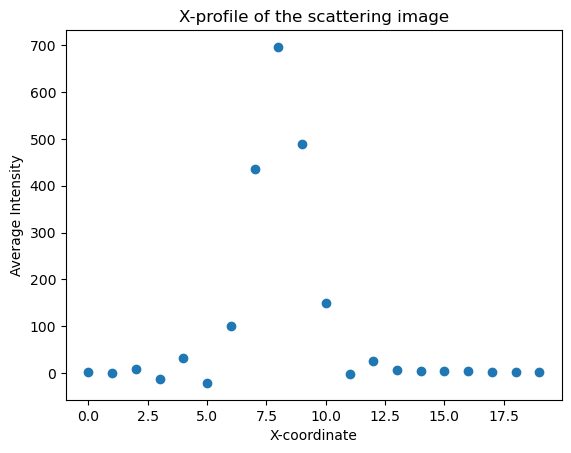

In [21]:
x_profile = np.mean(Iframes_avg_sg, axis=0)  # Calculate average intensity along the y-axis

# Create the plot

plt.plot(x_profile, 'o')

plt.xlabel("X-coordinate")

plt.ylabel("Average Intensity")

plt.title("X-profile of the scattering image")

plt.show()

[[Model]]
    Model(pvoigt)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 648
    # data points      = 20
    # variables        = 4
    chi-square         = 0.00298430
    reduced chi-square = 1.8652e-04
    Akaike info crit   = -168.202444
    Bayesian info crit = -164.219515
    R-squared          = 0.98220517
[[Variables]]
    amplitude:  2.95696366 +/- 0.10926159 (3.70%) (init = 2000)
    center:     9.79343636 +/- 0.08488033 (0.87%) (init = 10)
    sigma:      2.99157848 +/- 0.17233780 (5.76%) (init = 0.032)
    fraction:   0.99999999 +/- 0.07517166 (7.52%) (init = 0.5)
    fwhm:       5.98315695 +/- 0.34467560 (5.76%) == '2.0000000*sigma'
    height:     0.31462680 +/- 0.03203596 (10.18%) == '(((1-fraction)*amplitude)/max(1e-15, (sigma*sqrt(pi/log(2))))+(fraction*amplitude)/max(1e-15, (pi*sigma)))'
[[Correlations]] (unreported correlations are < 0.100)
    C(sigma, fraction)     = +0.6884
    C(amplitude, fraction) = -0.6040


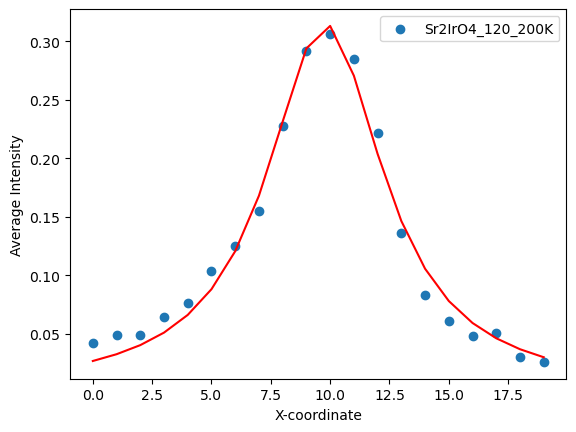

In [19]:
import lmfit
Xdata=x_profile
Int_X=Xdata-0.55
X= list(range(0, 20))
#X=Q_xs
model = lmfit.models.PseudoVoigtModel()
params = model.make_params(amplitude=2000, center=10, sigma=0.032)
#params['sigma'].vary = False
#params['center'].vary = False
result = model.fit(Int_X, params, x=X)
print(result.fit_report())
plt.scatter(X, Int_X, label='Sr2IrO4_120_200K')
plt.legend()
plt.ylabel("Average Intensity")
plt.xlabel("X-coordinate")
plt.plot(X, result.best_fit, 'r-')
plt.show()

In [20]:
Io = np.nanmean(np.nanmean(Iframes[:,40:60,40:60],axis = 1),axis = 1)

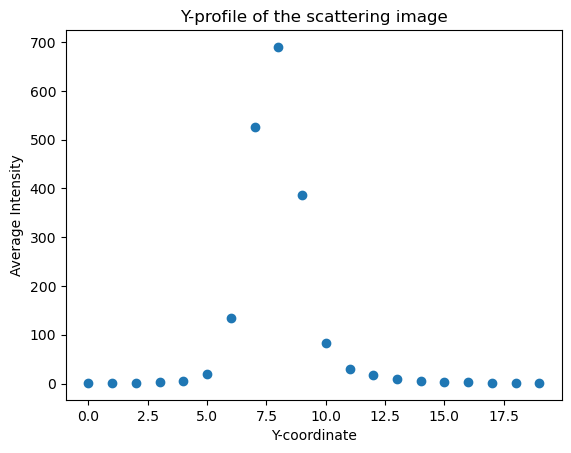

In [22]:
y_profile = np.mean(Iframes_avg_sg, axis=1)  # Calculate average intensity along the y-axis

# Create the plot

plt.plot(y_profile, 'o')

plt.xlabel("Y-coordinate")

plt.ylabel("Average Intensity")

plt.title("Y-profile of the scattering image")

plt.show()

[[Model]]
    Model(pvoigt)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 384
    # data points      = 20
    # variables        = 4
    chi-square         = 0.00447350
    reduced chi-square = 2.7959e-04
    Akaike info crit   = -160.106333
    Bayesian info crit = -156.123404
    R-squared          = 0.98620757
[[Variables]]
    amplitude:  2.63214564 +/- 0.09516800 (3.62%) (init = 2000)
    center:     10.2718669 +/- 0.05377827 (0.52%) (init = 9)
    sigma:      1.78695273 +/- 0.10962416 (6.13%) (init = 0.032)
    fraction:   0.99999998 +/- 0.19810840 (19.81%) (init = 0.5)
    fwhm:       3.57390547 +/- 0.21924832 (6.13%) == '2.0000000*sigma'
    height:     0.46886410 +/- 0.07518309 (16.04%) == '(((1-fraction)*amplitude)/max(1e-15, (sigma*sqrt(pi/log(2))))+(fraction*amplitude)/max(1e-15, (pi*sigma)))'
[[Correlations]] (unreported correlations are < 0.100)
    C(sigma, fraction)     = +0.7120
    C(amplitude, fraction) = -0.5413


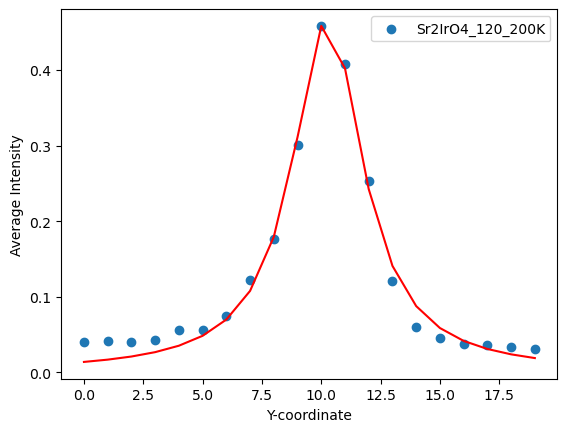

In [22]:
import lmfit
Ydata=y_profile
Int_Y=Ydata-0.55
X= list(range(0, 20))
#X=Q_xs
model = lmfit.models.PseudoVoigtModel()
params = model.make_params(amplitude=2000, center=9, sigma=0.032)
#params['sigma'].vary = False
#params['center'].vary = False
result = model.fit(Int_Y, params, x=X)
print(result.fit_report())
plt.scatter(X, Int_Y, label='Sr2IrO4_120_200K')
plt.legend()
plt.ylabel("Average Intensity")
plt.xlabel("Y-coordinate")
plt.plot(X, result.best_fit, 'r-')
plt.show()

In [24]:
Io = np.nanmean(np.nanmean(Iframes[:,10:13,5:8],axis = 1),axis = 1)

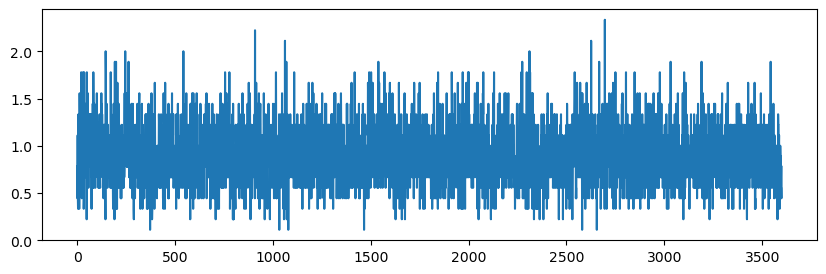

In [23]:
plt.figure(figsize=(10,3))
plt.plot(Io)

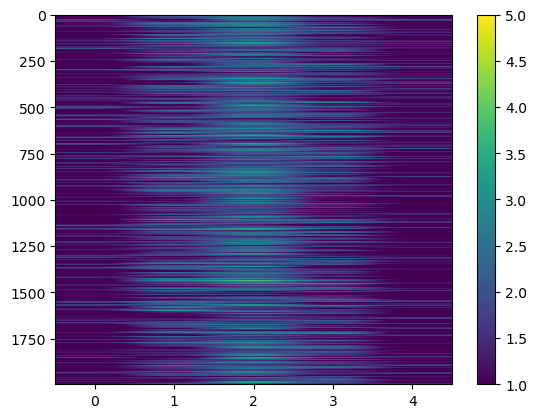

In [53]:
plt.imshow(Int[1:2000,8:13,9], vmin = 1, vmax = 5, aspect = 'auto')
#plt.imshow((np.abs(domain_ffts[1:200,170:320,238])), vmin = 50, vmax = 9040, aspect = 'auto')
plt.colorbar()

In [253]:
Ibkg = np.nanmean(Io, axis=0)

In [20]:
Ibkg

0.90396125

/tmp/ipykernel_201226/3521239375.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


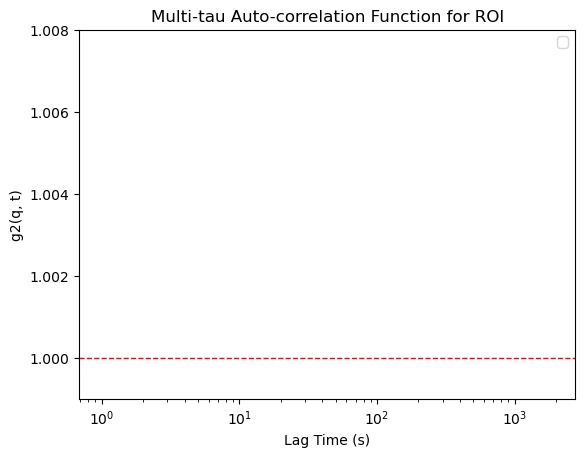

In [17]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt

# --- Define parameters for the multi-tau algorithm ---
num_levels = 6 # Number of multi-tau levels
num_bufs = 60 # Number of buffers to use at each level

#img_stack = Iframes[:].copy()
#img_stack = Int.copy() -Int.mean(0) -  np.min(Int.copy() -Int.mean(0))
img_stack = Int.copy() -Iframes_avg_sg - np.min(Int.copy() -Iframes_avg_sg)
#img_stack = Iframes.copy() -Iframes_avg_gf -  np.min(Iframes.copy() -Iframes_avg_gf)


#create 2D boolean array 'labeled_roi_array' where ROI box is 1
labeled_roi_array = np.zeros(img_stack.shape[1:3], dtype = np.int64)
#set ROI = 1
labeled_roi_array[0:20,0:20] = 1

# --- Calculate the multi-tau auto-correlation ---
g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,  # Your labeled ROI array
    img_stack[0:]  # Your image stack (as an iterable)
)

plt.semilogx(lag_steps[1:],(g2[1:]),'o',)
plt.xlabel('Lag Time (s)')
plt.ylabel('g2(q, t)')
plt.title('Multi-tau Auto-correlation Function for ROI')
plt.ylim(0.999,1.008)
plt.axhline(y=1, color='r', linestyle='--', linewidth=1)
plt.legend()
plt.show()
# --- Explanation of parameters ---
# num_levels: Controls the number of levels in the multi-tau algorithm, impacting the maximum lag time computed.
# num_bufs:  Controls the number of frames buffered at each level, impacting the number of lag times computed within each level.
# labeled_roi_array:  Defines the regions of interest (ROIs) on your detector images. Each pixel belonging to an ROI is assigned a unique label (an integer).
# img_stack:  An iterable containing your image data, typically a sequence of frames obtained from your XPCS experiment.

ROI 0
Intensity range: 175.0288 – 4669.5656
Number of ROI pixels: 40


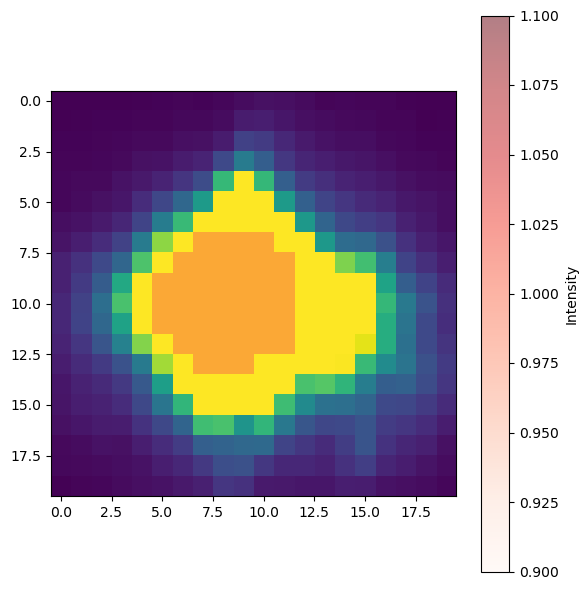

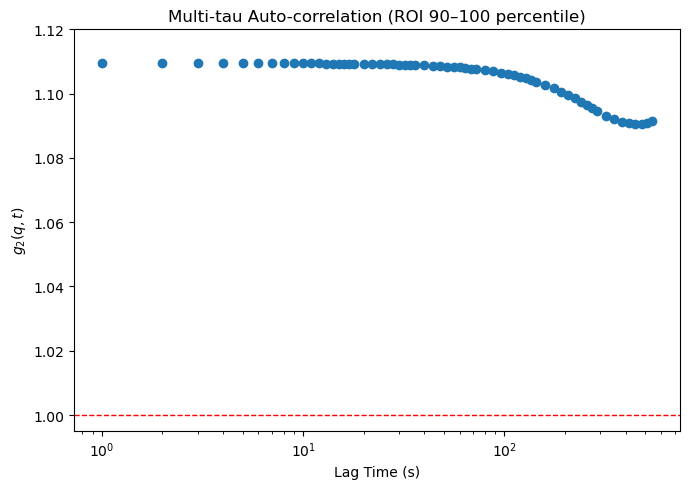

In [17]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt

# =============================================================
# Parameters
# =============================================================
num_levels = 6
num_bufs = 18

cutoffs = [100, 90, 80, 75, 70]
width = 1.0

# =============================================================
# Pre-processed image stack
# =============================================================
img_stack = (
    Int.copy()
    - Iframes_avg_sg
    - np.min(Int.copy() - Iframes_avg_sg)
)

# =============================================================
# Select the same ROI type as in the two-time correlation
# =============================================================

# Choose which percentile ROI to use
i = 0

cutoff_high = cutoffs[i]
cutoff_low = cutoff_high - width * (cutoff_high - cutoffs[i + 1])

# Calculate intensity thresholds
high_value = np.percentile(Iframes_avg_gf, cutoff_high)
low_value = np.percentile(Iframes_avg_gf, cutoff_low)

# Create ROI mask
roi_mask = (
    (Iframes_avg_gf <= high_value) &
    (Iframes_avg_gf > low_value)
)

# Create labeled ROI
labeled_roi_array = np.zeros(
    Iframes_avg_gf.shape,
    dtype=np.int64
)

labeled_roi_array[roi_mask] = 1

print(f"ROI {i}")
print(f"Intensity range: {low_value:.4f} – {high_value:.4f}")
print(f"Number of ROI pixels: {np.sum(roi_mask)}")

# =============================================================
# Show the same percentile-defined ROI
# =============================================================

mean_img = Int.copy().mean(axis=0)

plt.figure(figsize=(6, 6))

plt.imshow(
    mean_img,
    cmap='viridis',
    vmax=10
)

# Overlay ROI
plt.imshow(
    np.ma.masked_where(~roi_mask, roi_mask),
    cmap='Reds',
    alpha=0.5
)

plt.colorbar(label="Intensity")
plt.tight_layout()
plt.show()

# =============================================================
# Multi-tau autocorrelation
# =============================================================

g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,
    img_stack
)

# =============================================================
# Plot g2
# =============================================================

plt.figure(figsize=(7, 5))

plt.semilogx(
    lag_steps[1:],
    g2[1:],
    'o'
)

plt.ylim(0.995, 1.12)

plt.axhline(
    y=1,
    color='r',
    linestyle='--',
    linewidth=1
)

plt.xlabel('Lag Time (s)')
plt.ylabel(r'$g_2(q,t)$')

plt.title(
    f'Multi-tau Auto-correlation '
    f'(ROI {cutoff_low:.0f}–{cutoff_high:.0f} percentile)'
)

plt.tight_layout()
plt.show()

ROI 0
Percentile range: 90–100
Intensity range: 175.0288 – 4669.5656
Number of ROI pixels: 40


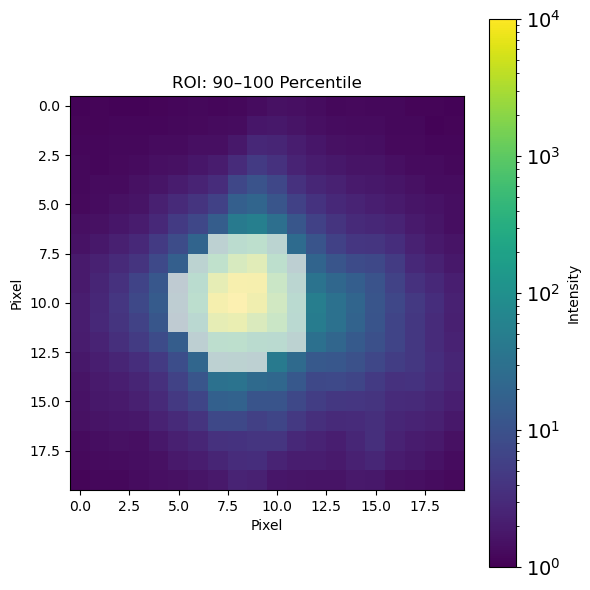

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


# =============================================================
# Parameters
# =============================================================

cutoffs = [100, 90, 80, 75, 70]
width = 1.0

# Choose which percentile ROI to use
i = 0


# =============================================================
# Define the same percentile ROI
# =============================================================

cutoff_high = cutoffs[i]

cutoff_low = (
    cutoff_high
    - width * (cutoff_high - cutoffs[i + 1])
)


# =============================================================
# Calculate intensity thresholds
# =============================================================

high_value = np.percentile(
    Iframes_avg_gf,
    cutoff_high
)

low_value = np.percentile(
    Iframes_avg_gf,
    cutoff_low
)


# =============================================================
# Create ROI mask
# =============================================================

roi_mask = (
    (Iframes_avg_gf <= high_value)
    & (Iframes_avg_gf > low_value)
)


# =============================================================
# Print ROI information
# =============================================================

print(f"ROI {i}")

print(
    f"Percentile range: "
    f"{cutoff_low:.0f}–{cutoff_high:.0f}"
)

print(
    f"Intensity range: "
    f"{low_value:.4f} – {high_value:.4f}"
)

print(
    f"Number of ROI pixels: "
    f"{np.sum(roi_mask)}"
)


# =============================================================
# Mean image
# =============================================================

mean_img = Int.copy().mean(axis=0)


# =============================================================
# Determine positive intensity range for log scale
# =============================================================

positive_values = mean_img[
    np.isfinite(mean_img)
    & (mean_img > 0)
]

if positive_values.size == 0:
    raise ValueError(
        "Mean image contains no positive values for logarithmic scaling."
    )

image_vmin = np.min(positive_values)
image_vmax = np.max(positive_values)


# =============================================================
# Plot percentile-defined ROI
# =============================================================

plt.figure(figsize=(6, 6))


# -------------------------------------------------------------
# Plot mean image with logarithmic intensity scale
# -------------------------------------------------------------

plt.imshow(
    mean_img,
    cmap="viridis",
    norm=LogNorm(
        vmin=1,
        vmax=10000
    )
)


# -------------------------------------------------------------
# Add colorbar
# -------------------------------------------------------------

cbar = plt.colorbar(label="Intensity")
cbar.ax.tick_params(labelsize=14)


# -------------------------------------------------------------
# Overlay ROI
# -------------------------------------------------------------

roi_overlay = np.ma.masked_where(
    ~roi_mask,
    roi_mask
)

plt.imshow(
    roi_overlay,
    cmap="Reds",
    alpha=0.7
)


# =============================================================
# Labels and title
# =============================================================

plt.xlabel(
    "Pixel"
)

plt.ylabel(
    "Pixel"
)

plt.title(
    f"ROI: {cutoff_low:.0f}–{cutoff_high:.0f} Percentile"
)


plt.tight_layout()


# =============================================================
# Save figure
# =============================================================

plt.savefig(
    f"324_ROI_{cutoff_low:.0f}-{cutoff_high:.0f}_percentile_log_200K.png",
    dpi=300,
    bbox_inches="tight"
)


# =============================================================
# Show
# =============================================================

plt.show()

In [25]:
g2_q = g2[1:].reshape(-1)

Fitted Parameters:
beta: 0.033 ± 0.008
tau_c: 500.000 ± 167.415
alpha: 1.176 ± 0.126
baseline: 1.077 ± 0.008


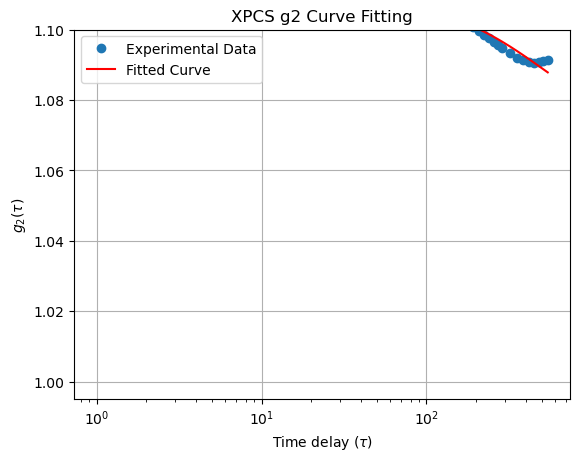

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the model function for the g2 curve
# A common model for XPCS is the stretched exponential decay
# g2(tau) = 1 + beta * exp(-(tau/tau_c)^alpha)
def g2_stretched_exponential(tau, beta, tau_c, alpha, baseline):
  """
  Stretched exponential fitting function for XPCS g2 curves.

  Args:
    tau: The time delay (independent variable).
    beta: The amplitude (contrast).
    tau_c: The characteristic decay time.
    alpha: The stretching exponent.
    baseline: The baseline value of the correlation function (ideally 1).

  Returns:
    The calculated g2 value at time delay tau.
  """
  return baseline + beta * np.exp(-(tau/tau_c)**alpha)

# Assuming you have your experimental data in arrays:
# xdata: time delays (tau)
# ydata: g2 values

# Example data (replace with your actual data)
xdata = lag_steps[1:]
ydata =  g2_q

# Initial guess for the fitting parameters
# It's important to provide good initial guesses for the fit to converge well
p0 = [0.012, 1000, 1.0, 0.95] # [beta, tau_c, alpha, baseline]

# Fixing a Parameter: Example - fixing the baseline to 1.0
# You can use the 'bounds' argument in curve_fit to constrain parameters.
# In this case, set the lower and upper bound for the baseline parameter to 1.0
# The order of the bounds should correspond to the order of the parameters in the function definition.
lower_bounds = [0.002, 200, 0.2, 0.9] # Bounds for [beta, tau_c, alpha, baseline]
upper_bounds = [0.18, 1320, 2.5, 1.1]

# Perform the curve fit
# Pass the function, data, initial guess, and bounds to curve_fit.
popt, pcov = curve_fit(g2_stretched_exponential, xdata, ydata, p0=p0, bounds=(lower_bounds, upper_bounds))

# Extract the fitted parameters and their uncertainties
fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline = popt
perr = np.sqrt(np.diag(pcov)) # Diagonal of covariance matrix gives parameter variances

print("Fitted Parameters:")
print(f"beta: {fitted_beta:.3f} ± {perr[0]:.3f}")
print(f"tau_c: {fitted_tau_c:.3f} ± {perr[1]:.3f}")
print(f"alpha: {fitted_alpha:.3f} ± {perr[2]:.3f}")
print(f"baseline: {fitted_baseline:.3f} ± {perr[3]:.3f}") # Uncertainty will be 0 as it was fixed

# Generate data for the fitted curve for plotting
tau_fit = np.linspace(min(xdata), max(xdata), 100) # Creates a smooth curve
g2_fit = g2_stretched_exponential(tau_fit, *popt) # Calculate g2 values using fitted parameters

# Calculate the fitted curve using the optimized parameters
yfit = g2_stretched_exponential(xdata, fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline)

# Plot the data and the fitted curve
plt.figure()
plt.semilogx(xdata, ydata, 'o', label='Experimental Data')
plt.semilogx(xdata, yfit, 'r-', label='Fitted Curve')
#plt.plot(xdata, ydata, 'o', label='Experimental Data')
#plt.plot(xdata, yfit, 'r-', label='Fitted Curve')
plt.xlabel('Time delay ($\\tau$)')
plt.ylabel('$g_2(\\tau)$')
plt.title('XPCS g2 Curve Fitting')
plt.ylim(0.995,1.12)
plt.legend()
plt.grid(True)
plt.show()

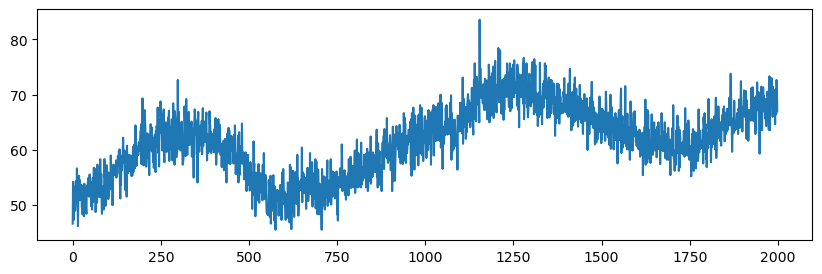

In [18]:
I_ROI = np.nanmean(np.nanmean(Int[:,5:8,9:12],axis = 1),axis = 1)
plt.figure(figsize=(10,3))
plt.plot(I_ROI)

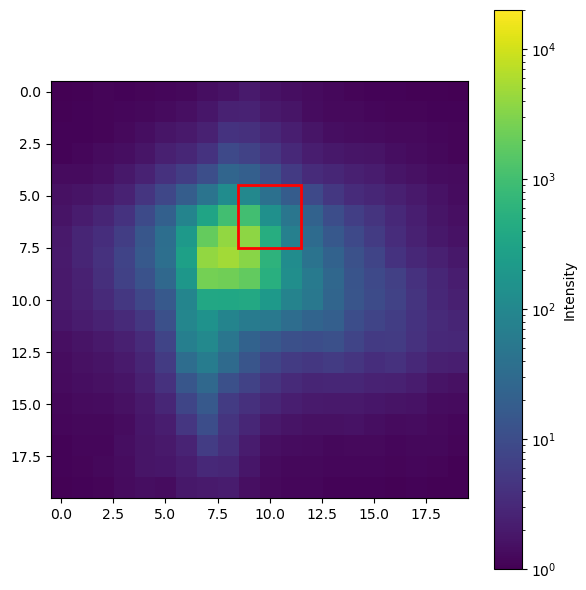

<module 'matplotlib.pyplot' from '/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/matplotlib/pyplot.py'>

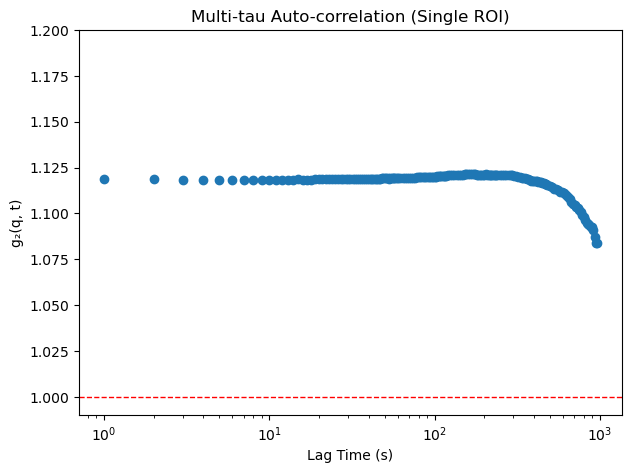

In [26]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- Parameters ---
num_levels = 6
num_bufs = 60

# Pre-processed image stack
#img_stack = Int.copy() - Iframes_avg_sg - np.min(Int.copy() - Iframes_avg_sg)
img_stack = Int[1000:].copy() - Iframes_avg_sg \
            - np.min(Int[1000:].copy() - Iframes_avg_sg)

# -------------------------------------------------------------
# Create labeled ROI
# -------------------------------------------------------------
labeled_roi_array = np.zeros(img_stack.shape[1:3], dtype=np.int64)

# Define ROI box
#r0, r1 = 11, 12   # row start, row end  Y
#c0, c1 = 7, 8    # col start, col end  X

r0, r1 = 5, 8   # row start, row end  Y
c0, c1 = 9, 12    # col start, col end  X
labeled_roi_array[r0:r1, c0:c1] = 1

# -------------------------------------------------------------
# --- Show 2D mean image with ROI box ---
# -------------------------------------------------------------

mean_img = Int.copy().mean(axis=0)

plt.figure(figsize=(6, 6))
#plt.imshow(mean_img, cmap='viridis', vmax=10)
plt.imshow(mean_img, cmap='viridis', norm=LogNorm(vmin=1, vmax=20000))
#plt.title("ROI on Top of Mean Image")
plt.colorbar(label="Intensity")

# Draw yellow hollow rectangle around ROI
rect = patches.Rectangle(
    (c0-0.5, r0-0.5),
    c1 - c0,
    r1 - r0,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)
plt.gca().add_patch(rect)

#plt.text(c0, r0 - 3, "ROI", color="yellow", fontsize=12)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# --- Multi-tau autocorrelation ---
# -------------------------------------------------------------
g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,
    img_stack
)

# -------------------------------------------------------------
# Plot g2
# -------------------------------------------------------------
plt.figure(figsize=(7, 5))
plt.semilogx(lag_steps[1:], g2[1:], 'o')
plt.ylim(0.99,1.2)
plt.axhline(y=1, color='r', linestyle='--', linewidth=1)
plt.xlabel('Lag Time (s)')
plt.ylabel('g₂(q, t)')
plt.title('Multi-tau Auto-correlation (Single ROI)')
plt


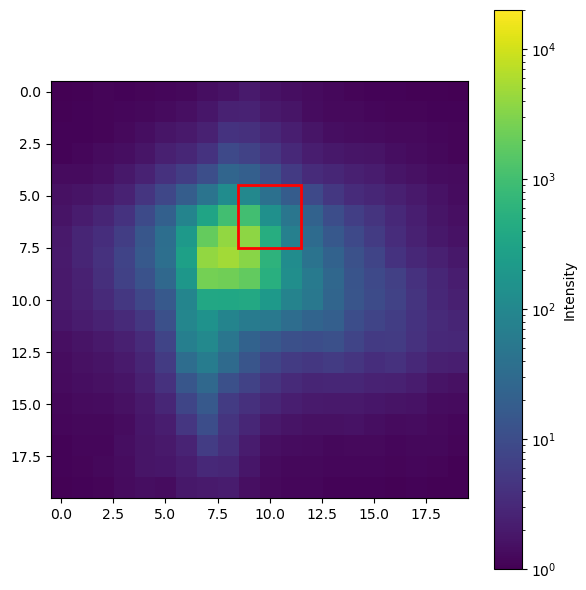

<module 'matplotlib.pyplot' from '/nsls2/software/common/jupyter/kernel_envs/current/.pixi/envs/default/lib/python3.12/site-packages/matplotlib/pyplot.py'>

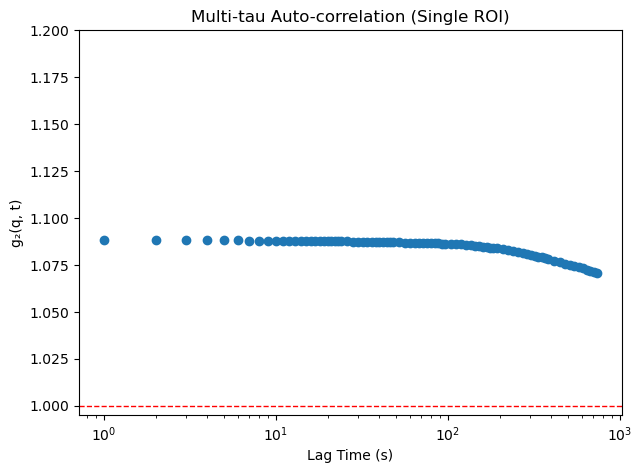

In [19]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- Parameters ---
num_levels = 6
num_bufs = 24

# Pre-processed image stack
img_stack = Int.copy() - Iframes_avg_sg - np.min(Int.copy() - Iframes_avg_sg)

# -------------------------------------------------------------
# Create labeled ROI
# -------------------------------------------------------------
labeled_roi_array = np.zeros(img_stack.shape[1:3], dtype=np.int64)

# Define ROI box
r0, r1 = 5, 8   # row start, row end  Y
c0, c1 = 9, 12    # col start, col end  X
labeled_roi_array[r0:r1, c0:c1] = 1

# -------------------------------------------------------------
# --- Show 2D mean image with ROI box ---
# -------------------------------------------------------------

mean_img = Int.copy().mean(axis=0)

plt.figure(figsize=(6, 6))
#plt.imshow(mean_img, cmap='viridis', vmax=10)
plt.imshow(mean_img, cmap='viridis', norm=LogNorm(vmin=1, vmax=20000))
#plt.title("ROI on Top of Mean Image")
plt.colorbar(label="Intensity")

# Draw yellow hollow rectangle around ROI
rect = patches.Rectangle(
    (c0-0.5, r0-0.5),
    c1 - c0,
    r1 - r0,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)
plt.gca().add_patch(rect)

#plt.text(c0, r0 - 3, "ROI", color="yellow", fontsize=12)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# --- Multi-tau autocorrelation ---
# -------------------------------------------------------------
g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,
    img_stack
)

# -------------------------------------------------------------
# Plot g2
# -------------------------------------------------------------
plt.figure(figsize=(7, 5))
plt.semilogx(lag_steps[1:], g2[1:], 'o')
plt.ylim(0.995,1.2)
plt.axhline(y=1, color='r', linestyle='--', linewidth=1)
plt.xlabel('Lag Time (s)')
plt.ylabel('g₂(q, t)')
plt.title('Multi-tau Auto-correlation (Single ROI)')
plt


In [33]:
g2_q = g2[1:].reshape(-1)

Fitted Parameters:
beta: 0.011 ± 0.000
tau_c: 328.515 ± 4.785
alpha: 2.095 ± 0.058
baseline: 1.021 ± 0.000


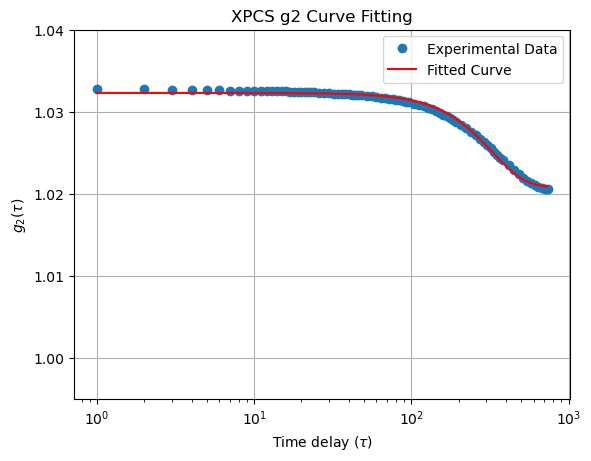

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the model function for the g2 curve
# A common model for XPCS is the stretched exponential decay
# g2(tau) = 1 + beta * exp(-(tau/tau_c)^alpha)
def g2_stretched_exponential(tau, beta, tau_c, alpha, baseline):
  """
  Stretched exponential fitting function for XPCS g2 curves.

  Args:
    tau: The time delay (independent variable).
    beta: The amplitude (contrast).
    tau_c: The characteristic decay time.
    alpha: The stretching exponent.
    baseline: The baseline value of the correlation function (ideally 1).

  Returns:
    The calculated g2 value at time delay tau.
  """
  return baseline + beta * np.exp(-(tau/tau_c)**alpha)

# Assuming you have your experimental data in arrays:
# xdata: time delays (tau)
# ydata: g2 values

# Example data (replace with your actual data)
xdata = lag_steps[1:]
ydata =  g2_q

# Initial guess for the fitting parameters
# It's important to provide good initial guesses for the fit to converge well
p0 = [0.010, 1000, 2.2, 0.95] # [beta, tau_c, alpha, baseline]

# Fixing a Parameter: Example - fixing the baseline to 1.0
# You can use the 'bounds' argument in curve_fit to constrain parameters.
# In this case, set the lower and upper bound for the baseline parameter to 1.0
# The order of the bounds should correspond to the order of the parameters in the function definition.
lower_bounds = [0.002, 200, 2.095, 0.9] # Bounds for [beta, tau_c, alpha, baseline]
upper_bounds = [0.18, 1320, 2.5, 1.5]

# Perform the curve fit
# Pass the function, data, initial guess, and bounds to curve_fit.
popt, pcov = curve_fit(g2_stretched_exponential, xdata, ydata, p0=p0, bounds=(lower_bounds, upper_bounds))

# Extract the fitted parameters and their uncertainties
fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline = popt
perr = np.sqrt(np.diag(pcov)) # Diagonal of covariance matrix gives parameter variances

print("Fitted Parameters:")
print(f"beta: {fitted_beta:.3f} ± {perr[0]:.3f}")
print(f"tau_c: {fitted_tau_c:.3f} ± {perr[1]:.3f}")
print(f"alpha: {fitted_alpha:.3f} ± {perr[2]:.3f}")
print(f"baseline: {fitted_baseline:.3f} ± {perr[3]:.3f}") # Uncertainty will be 0 as it was fixed

# Generate data for the fitted curve for plotting
tau_fit = np.linspace(min(xdata), max(xdata), 100) # Creates a smooth curve
g2_fit = g2_stretched_exponential(tau_fit, *popt) # Calculate g2 values using fitted parameters

# Calculate the fitted curve using the optimized parameters
yfit = g2_stretched_exponential(xdata, fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline)

# Plot the data and the fitted curve
plt.figure()
plt.semilogx(xdata, ydata, 'o', label='Experimental Data')
plt.semilogx(xdata, yfit, 'r-', label='Fitted Curve')
#plt.plot(xdata, ydata, 'o', label='Experimental Data')
#plt.plot(xdata, yfit, 'r-', label='Fitted Curve')
plt.xlabel('Time delay ($\\tau$)')
plt.ylabel('$g_2(\\tau)$')
plt.title('XPCS g2 Curve Fitting')
plt.ylim(0.995,1.04)
plt.legend()
plt.grid(True)
plt.show()

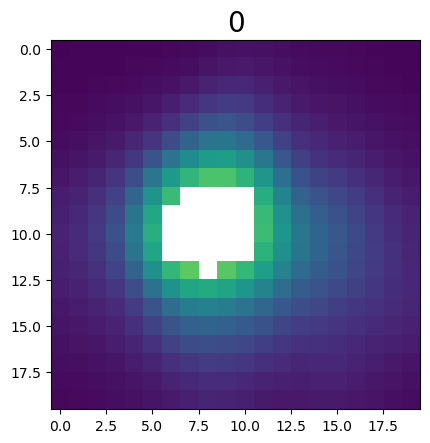

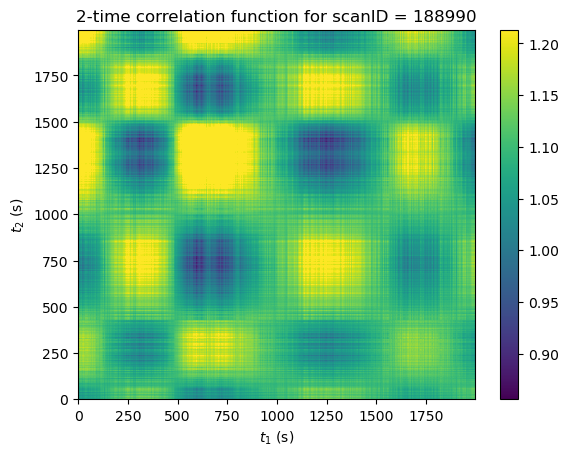

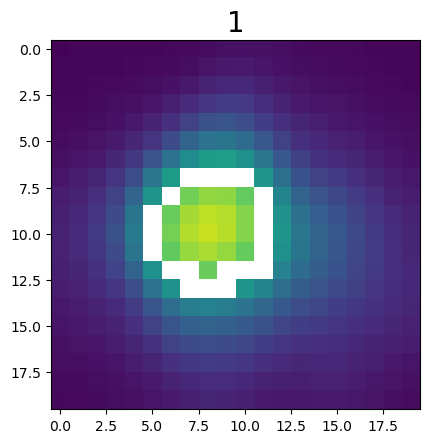

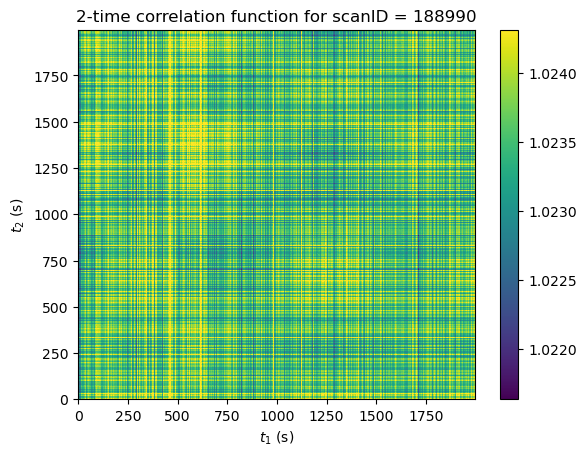

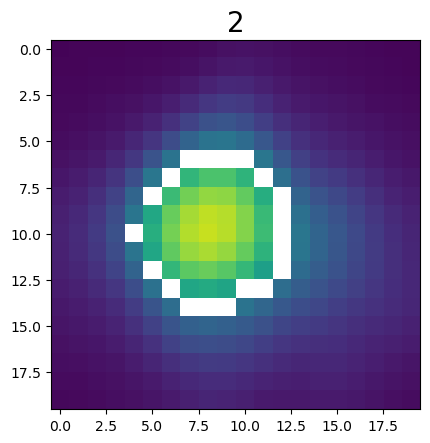

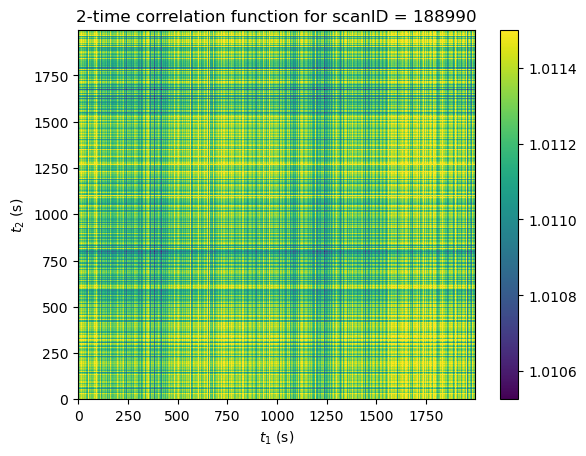

In [18]:
from skbeam.core import correlation as corr
F_all = []
g_all = []

colormap = np.zeros(Iframes.shape[1:3], dtype = np.int64 )
#Iframes = Iframes[:500]    

#Io = np.mean(np.mean(np.array(Iframes), axis = 1), axis = 1)
#Iframes = Iframes/Io[:,None,None]


cutoffs =  [100, 95, 90, 85, 80 ]
width = 1.0 #30% filling
    
for i in range(len(cutoffs)-2):
    
    #dataNorm = Iframes[:].copy() #- Iframes.mean(0)
    dataNorm = Int.copy() - Iframes_avg_sg - np.min(Int.copy() - Iframes_avg_sg)

    cutoff_high = cutoffs[i]
    cutoff_low = cutoffs[i] - width*(cutoffs[i]-cutoffs[i+1]) # width is 50%
    #print([cutoff_high, cutoff_low])

    #plot ROI region
    Iframes_avg_gf_temp = Iframes_avg_gf.copy()
    Iframes_avg_gf_temp[np.logical_and(Iframes_avg_gf_temp <= np.percentile(Iframes_avg_gf,cutoff_high), np.percentile(Iframes_avg_gf,cutoff_low) < Iframes_avg_gf_temp)]=0
    plt.figure()
    #plt.imshow(Iframes_avg_gf_temp,vmax = 5)
    plt.imshow(Iframes_avg_gf_temp, cmap='viridis', norm=LogNorm(vmin=1, vmax=10000))
    plt.title(str(i), fontsize = 20)

    #create 2D boolean array 'labeled_roi_array' where ROI box is 1
    labeled_roi_array = np.zeros(dataNorm.shape[1:3], dtype = np.int64 )

    #set ROI = 1
    labeled_roi_array[np.logical_and(Iframes_avg_gf <= np.percentile(Iframes_avg_gf,cutoff_high), np.percentile(Iframes_avg_gf,cutoff_low) < Iframes_avg_gf)]= 1

    #----------

    corr_12, lag_steps, internal_state = corr.two_time_corr(labels = labeled_roi_array, images = dataNorm[2:], num_frames = dataNorm[2:].shape[0], num_bufs = dataNorm[1:].shape[0], num_levels = 1)

    X, Y = np.meshgrid(lag_steps, lag_steps)

    plt.figure()
    plt.xlabel('$t_1$ (s)')
    plt.ylabel('$t_2$ (s)')
    plt.title(f'2-time correlation function for scanID = {uid}')
    plt.pcolor(X, Y, np.flipud(corr_12[0]), vmax = np.percentile(corr_12[0],95))
    plt.colorbar()
    
    

ROI 1: 95.00 - 100.00 percentile


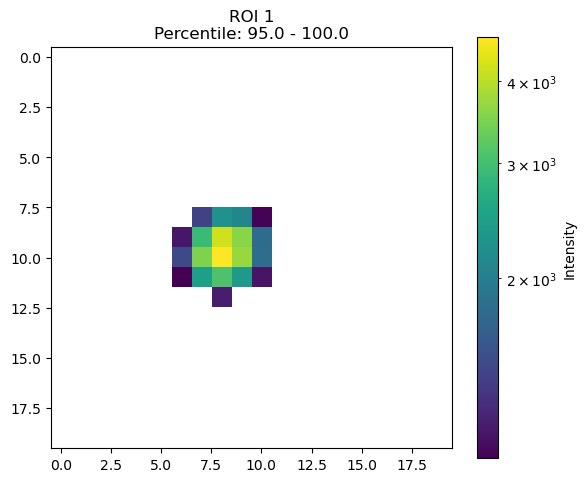

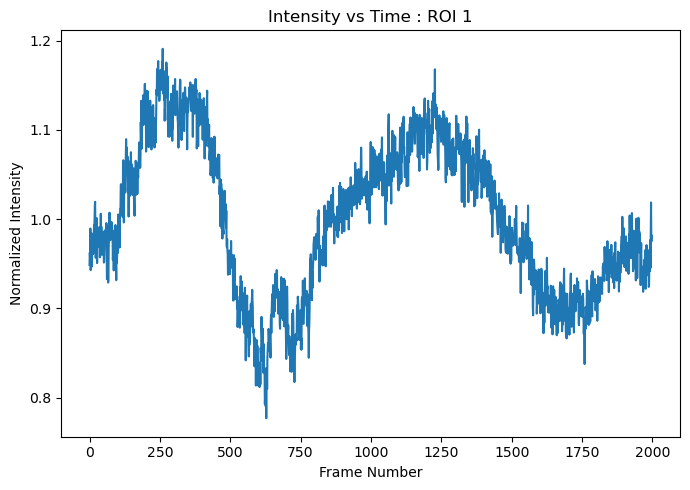

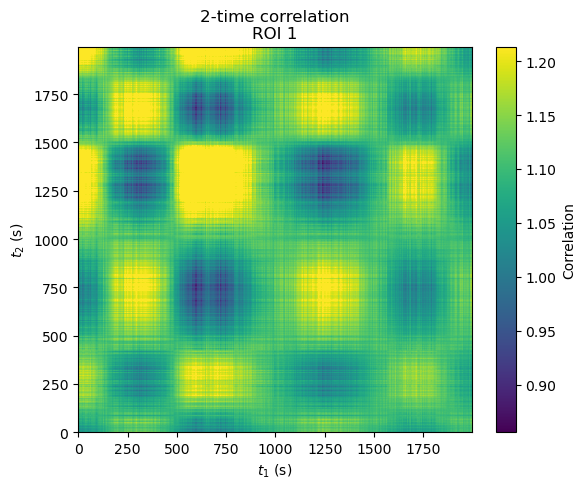

ROI 2: 90.00 - 95.00 percentile


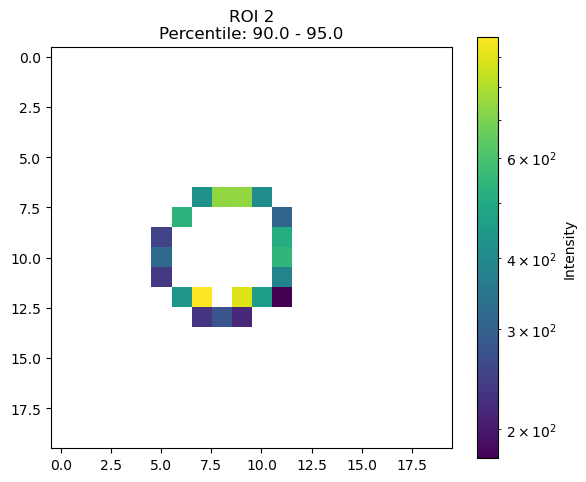

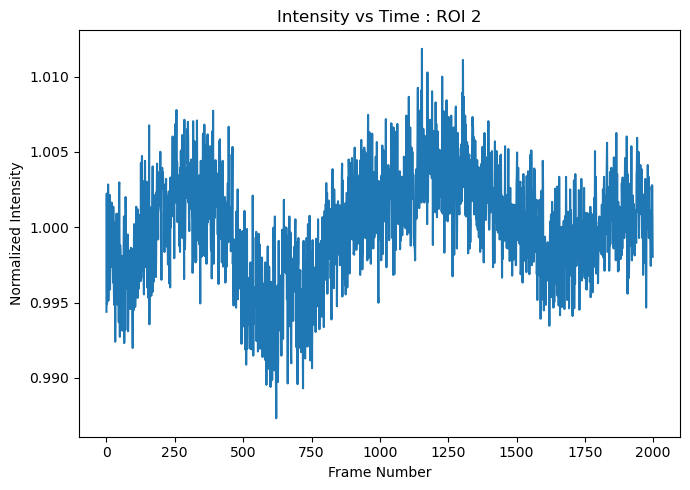

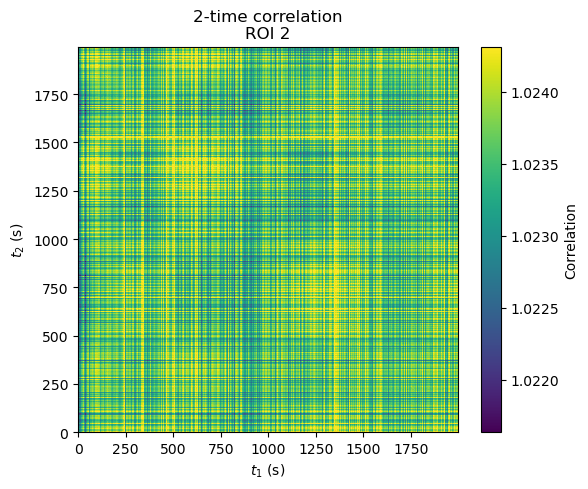

ROI 3: 85.00 - 90.00 percentile


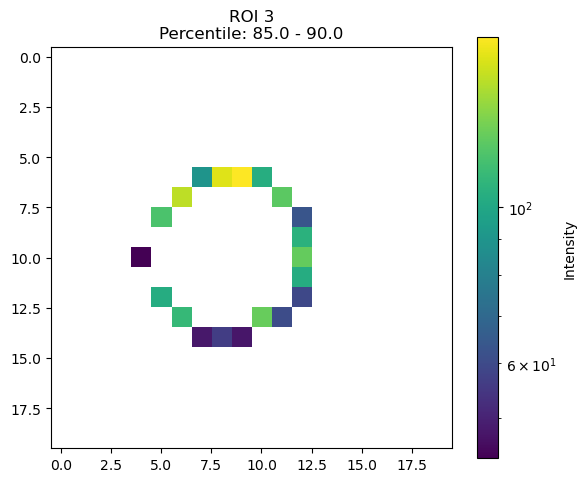

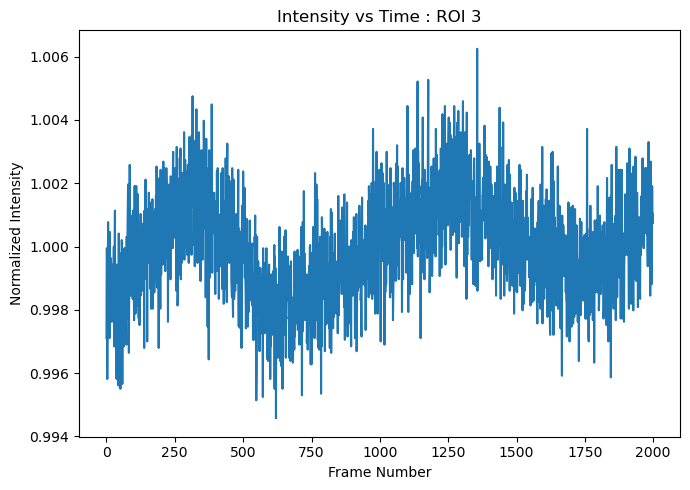

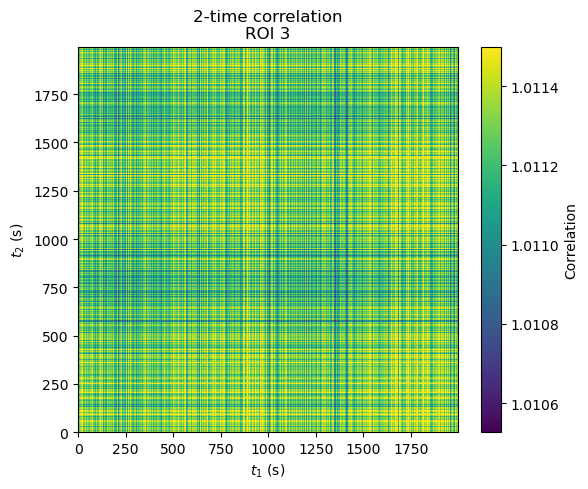

In [19]:
from skbeam.core import correlation as corr
from matplotlib.colors import LogNorm
import numpy as np
import matplotlib.pyplot as plt

F_all = []
g_all = []

colormap = np.zeros(Iframes.shape[1:3], dtype=np.int64)

# ----------------------------------------
# Percentile shells
# ----------------------------------------

cutoffs = [100, 95, 90, 85, 80]
width = 1.0

# ----------------------------------------
# Background-subtracted data
# ----------------------------------------

dataNorm = Int.copy() - Iframes_avg_sg
dataNorm = dataNorm - np.min(dataNorm)

# ----------------------------------------
# Loop over ROIs
# ----------------------------------------

for i in range(len(cutoffs)-2):

    cutoff_high = cutoffs[i]

    cutoff_low = (
        cutoffs[i]
        - width * (cutoffs[i] - cutoffs[i+1])
    )

    print(f'ROI {i+1}: {cutoff_low:.2f} - {cutoff_high:.2f} percentile')

    # ----------------------------------------
    # ROI mask
    # ----------------------------------------

    high_val = np.percentile(Iframes_avg_gf, cutoff_high)
    low_val  = np.percentile(Iframes_avg_gf, cutoff_low)

    roi_mask = np.logical_and(
        Iframes_avg_gf <= high_val,
        Iframes_avg_gf > low_val
    )

    # ----------------------------------------
    # Show ROI region
    # ----------------------------------------

    roi_display = np.zeros_like(Iframes_avg_gf)

    roi_display[roi_mask] = Iframes_avg_gf[roi_mask]

    plt.figure(figsize=(6,5))

    plt.imshow(
        roi_display,
        cmap='viridis',
        norm=LogNorm(
            vmin=max(np.min(roi_display[roi_mask]), 1e-3),
            vmax=np.max(roi_display[roi_mask])
        )
    )

    plt.colorbar(label='Intensity')

    plt.title(
        f'ROI {i+1}\n'
        f'Percentile: {cutoff_low:.1f} - {cutoff_high:.1f}'
    )

    plt.tight_layout()
    plt.show()

    # ----------------------------------------
    # Intensity vs time for this ROI
    # ----------------------------------------

    I_t = np.mean(dataNorm[:, roi_mask], axis=1)

    # normalize
    I_t = I_t / np.mean(I_t)

    plt.figure(figsize=(7,5))

    plt.plot(I_t)

    plt.xlabel('Frame Number')
    plt.ylabel('Normalized Intensity')

    plt.title(f'Intensity vs Time : ROI {i+1}')

    plt.tight_layout()
    plt.show()

    # ----------------------------------------
    # Create labeled ROI array
    # ----------------------------------------

    labeled_roi_array = np.zeros(
        dataNorm.shape[1:3],
        dtype=np.int64
    )

    labeled_roi_array[roi_mask] = 1

    # ----------------------------------------
    # Two-time correlation
    # ----------------------------------------

    images = dataNorm[2:]

    num_bufs = images.shape[0]

    # skbeam requires even num_bufs
    if num_bufs % 2 != 0:
        num_bufs -= 1

    images = images[:num_bufs]

    corr_12, lag_steps, internal_state = corr.two_time_corr(
        labels=labeled_roi_array,
        images=images,
        num_frames=num_bufs,
        num_bufs=num_bufs,
        num_levels=1
    )

    # ----------------------------------------
    # Plot 2-time correlation
    # ----------------------------------------

    X, Y = np.meshgrid(lag_steps, lag_steps)

    plt.figure(figsize=(6,5))

    plt.xlabel(r'$t_1$ (s)')
    plt.ylabel(r'$t_2$ (s)')

    plt.title(
        f'2-time correlation\n'
        f'ROI {i+1}'
    )

    plt.pcolor(
        X,
        Y,
        np.flipud(corr_12[0]),
        vmax=np.percentile(corr_12[0], 95),
        shading='auto'
    )

    plt.colorbar(label='Correlation')

    plt.tight_layout()
    plt.show()

    # ----------------------------------------
    # Store results
    # ----------------------------------------

    F_all.append(corr_12)
    g_all.append(lag_steps)

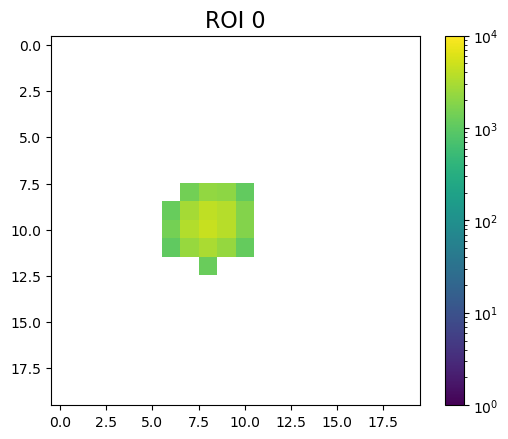

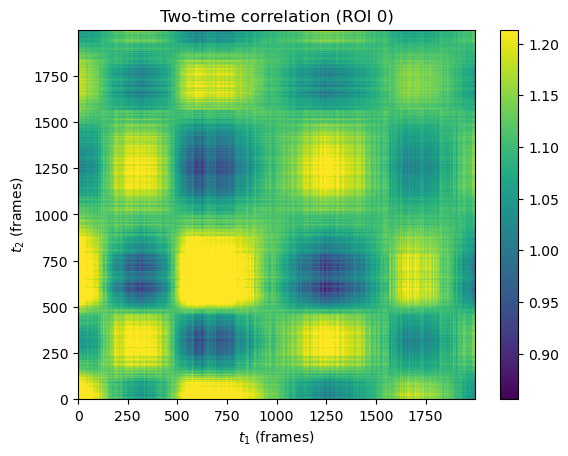

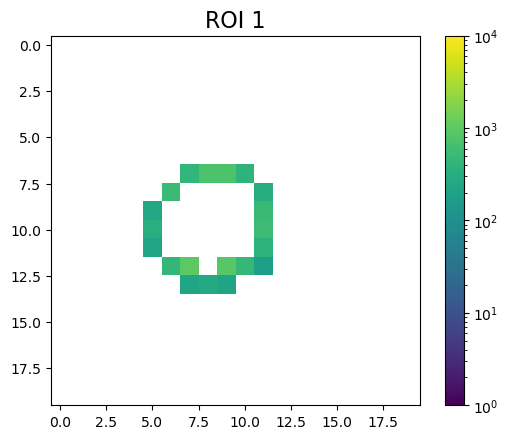

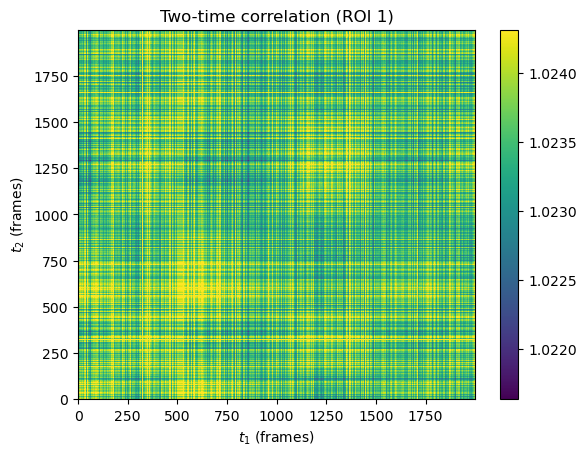

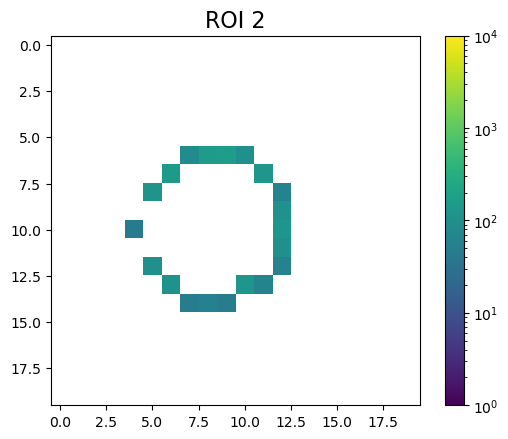

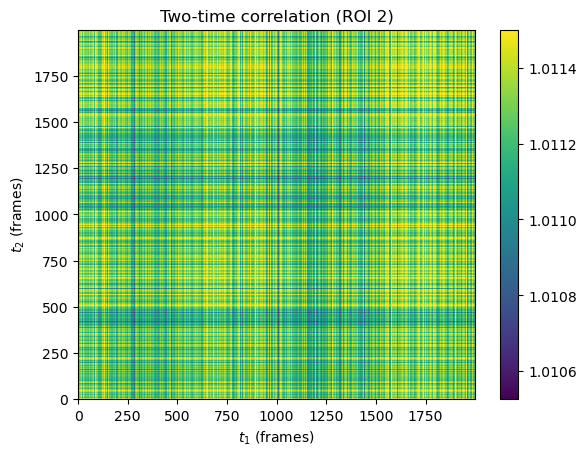

In [20]:
from skbeam.core import correlation as corr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

F_all = []
g_all = []

cutoffs = [100, 95, 90, 85, 80]
width = 1.0  # fraction of bin width

# full normalized data (do NOT recompute inside loop)
dataNorm = Int.copy() - Iframes_avg_sg
dataNorm -= np.min(dataNorm)

n_frames = dataNorm.shape[0]

for i in range(len(cutoffs) - 2):

    cutoff_high = cutoffs[i]
    cutoff_low = cutoffs[i] - width * (cutoffs[i] - cutoffs[i + 1])

    # ---- ROI selection ----
    roi_mask = np.logical_and(
        Iframes_avg_gf <= np.percentile(Iframes_avg_gf, cutoff_high),
        Iframes_avg_gf > np.percentile(Iframes_avg_gf, cutoff_low)
    )

    labeled_roi_array = np.zeros(dataNorm.shape[1:3], dtype=np.int32)
    labeled_roi_array[roi_mask] = 1

    # ---- visualize ROI ----
    plt.figure()
    plt.imshow(Iframes_avg_gf * roi_mask, cmap='viridis',
               norm=LogNorm(vmin=1, vmax=10000))
    plt.title(f"ROI {i}", fontsize=16)
    plt.colorbar()

    # ---- two-time correlation ----
    corr_2t, lag_steps, internal_state = corr.two_time_corr(
        labels=labeled_roi_array,
        images=dataNorm,
        num_frames=n_frames,
        num_bufs=n_frames+1,
        num_levels=1
    )

    # ---- plot two-time map ----
    X, Y = np.meshgrid(lag_steps, lag_steps)

    plt.figure()
    plt.xlabel(r'$t_1$ (frames)')
    plt.ylabel(r'$t_2$ (frames)')
    plt.title(f'Two-time correlation (ROI {i})')

    plt.pcolor(X, Y, corr_2t[0],
               vmax=np.percentile(corr_2t[0], 95))
    plt.colorbar()
    plt.show()

In [ ]:
# Equal Q-Rings XPCS code 

In [415]:
import numpy as np

def angles_to_q(wavelength, omega, two_theta, chi, phi):
    """
    Convert diffractometer angles to scattering vector q in lab frame.
    All angles in degrees.
    """
    # Convert angles to radians
    omega = np.radians(omega)
    two_theta = np.radians(two_theta)
    chi = np.radians(chi)
    phi = np.radians(phi)

    # Incident wavevector k_i (unit vector along z-axis)
    k_i = np.array([0, -np.sin(omega), np.cos(omega)])

    # Scattered wavevector k_f in lab frame
    k_f = np.array([
        np.sin(two_theta/2)* np.sin(chi),
        np.sin(two_theta/2) * np.cos(chi),
        np.cos(two_theta/2)
    ])

    # Scattering vector q = k_f - k_i (in units of 1/λ)
    q_lab = (k_f - k_i) * (2 * np.pi / wavelength)

    return q_lab

def q_to_hkl_tetragonal(q_lab, a, c):
    """
    Convert scattering vector q in lab frame to fractional (h,k,l) using tetragonal lattice.
    Assumes a = b ≠ c.
    """
    # Reciprocal lattice constants
    a_star = 2 * np.pi / a
    c_star = 2 * np.pi / c

    # Reciprocal lattice basis vectors
    B = np.array([
        [a_star,     0,      0],
        [0,      a_star,     0],
        [0,          0,  c_star]
    ])

    # Invert to get fractional hkl
    hkl = np.linalg.solve(B, q_lab)
    return hkl

# === Example Usage ===
a = b = 5.499  # Å
c = 25.798     # Å
wavelength = 1.1055  # Å (e.g., typical synchrotron x-ray)


# Sample angles (in degrees)
omega = 13.0
two_theta = 26.0
chi = 63
phi = -6.3

# Compute q-vector
q = angles_to_q(wavelength, omega, two_theta, chi, phi)

# Compute (h, k, l)
hkl = q_to_hkl_tetragonal(q, a, c)

print("Scattering vector q (1/Å):", q)
print("Fractional hkl indices:", hkl)

Scattering vector q (1/Å): [1.13917393 1.8589629  0.        ]
Fractional hkl indices: [0.99699709 1.62695138 0.        ]


In [23]:
import numpy as np

def rotation_matrix_x(omega):
    c, s = np.cos(omega), np.sin(omega)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def rotation_matrix_y(phi):
    c, s = np.cos(phi), np.sin(phi)
    return np.array([[ c, 0, s],
                     [ 0, 1, 0],
                     [-s, 0, c]])

def rotation_matrix_z(chi):
    c, s = np.cos(chi), np.sin(chi)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])


def angles_to_q_lab(wavelength, omega_deg, two_theta_deg, chi_deg, phi_deg):
    """
    Convert diffractometer angles to scattering vector q in the lab frame.
    All angles in degrees.
    """
    # Convert to radians
    omega = np.radians(omega_deg)
    two_theta = np.radians(two_theta_deg)
    chi = np.radians(chi_deg)
    phi = np.radians(phi_deg)
    azi = np.radians(azi_deg)

    # Incident and exit wavevectors (unit vectors scaled by 2π/λ)
    k_mag = 2 * np.pi / wavelength

    # Incident beam along +z, rotated by omega
    k_i = np.array([0, 0, 1]) * k_mag

    # Exit beam in lab coordinates
    k_f = np.array([
        np.sin(two_theta) * np.cos(azi),
        np.sin(two_theta) * np.sin(azi),
        np.cos(two_theta)
    ]) * k_mag

    # Scattering vector in lab frame
    q_lab = k_f - k_i
    return q_lab

def q_lab_to_hkl_tetragonal(q_lab, a, c, omega_deg, two_theta_deg, chi_deg, phi_deg):
    """
    Transform q from lab frame to crystal frame and convert to fractional hkl.
    """
    # Convert angles to radians
    omega = np.radians(omega_deg)
    two_theta = np.radians(two_theta_deg)
    chi = np.radians(chi_deg)
    phi = np.radians(phi_deg)
    azi = np.radians(azi_deg)

    # Orientation matrix: R_phi * R_chi * R_omega
    R_phi = rotation_matrix_y(phi)
    R_chi = rotation_matrix_z(chi)
    R_omega = rotation_matrix_x(omega)

    R_total = R_phi @ R_chi @ R_omega
    
    # Extract 2×2 xy-rotation submatrix
    #R_xy = R_total[:2, :2]

    # Rotate xy part of q_lab
    #q_xy_rotated = R_xy.T @ q_lab[:2]  # inverse rotation for lab→crystal

    # Build full q_crystal vector (xy rotated, z unchanged)
    #q_crystal = np.array([q_xy_rotated[0],
                          #q_xy_rotated[1],
                          #q_lab[2]])

    q_crystal = np.linalg.inv(R_total) @ q_lab

    # Reciprocal lattice constants
    a_star = 2 * np.pi / a
    c_star = 2 * np.pi / c

    # Reciprocal lattice basis matrix
    B = np.array([
        [a_star, 0,       0],
        [0,      a_star,  0],
        [0,      0,       c_star]
    ])

    # Get fractional hkl
    hkl = np.linalg.solve(B, q_crystal)
    return hkl

# === Example usage ===
a = b = 5.499  # Å
c = 25.798     # Å
wavelength = 1.1055  # Å

# Angles in degrees
omega_deg =  6.06
two_theta_deg = 43.7
chi_deg = 36
phi_deg =5.0
azi_deg = 2.0

# Step 1: Get q in lab frame
q_lab = angles_to_q_lab(wavelength, omega_deg, two_theta_deg, chi_deg, phi_deg)

# Step 2: Convert to fractional hkl
hkl = q_lab_to_hkl_tetragonal(q_lab, a, c, omega_deg, two_theta_deg, chi_deg, phi_deg)

print("q_lab (1/Å):", q_lab)
print("Fractional hkl:", hkl)


q_lab (1/Å): [ 3.92428569  0.13703908 -1.57453529]
Fractional hkl: [ 2.93566302 -2.08686813 -4.02486922]


In [24]:
# You might need to manually determine the center
# of the scattering pattern from the displayed image.
# For example, if the center is at pixel (512, 512):
#Find the max intensity
max_intensity = np.max(Int.mean(0))

# Find the coordinates of the maximum intensity
y_coords, x_coords = np.where(Int.mean(0) == max_intensity) 

#center_y = y_coords[0]
#center_x = x_coords[0]

center_x = 9
center_y = 9

In [25]:
center_y

9

In [44]:
import math
#AFM Peak 120
#theta=12.98
#phi=0.5
#Bragg Peak 220
theta=13.00
phi=-6.3
chi = 63
Theta_rad=(math.pi/180)*theta
Phi_rad=(math.pi/180)*phi
Chi_rad=(math.pi/180)*chi
x_cen= 24
y_cen=24
SDD=150E8
D_pix=75E4
Ld=1.1055
X=10
Y=23
theta_x=math.atan(((x_cen-X)*D_pix)/(SDD))
theta_y=math.atan(((y_cen-Y)*D_pix)/(SDD))
Rad_Y=(math.pi/180)*theta_y
Rad_X=(math.pi/180)*theta_x
Q_z=((4*(math.pi))/Ld)*(math.sin(Theta_rad+Rad_Y/2))*(math.sin(Chi_rad))
Q_x=((2*(math.pi))/Ld)*(math.sin(Phi_rad+Rad_X))*(math.cos(Theta_rad))
Q_y=((2*(math.pi))/Ld)*((math.cos(Phi_rad+Rad_X))*(math.cos(Theta_rad)) - (math.cos(Theta_rad)))
Q_xy=math.sqrt((Q_y)**2 + (Q_x)**2)
Q = math.sqrt((Q_xy)**2 + (Q_z)**2)

In [26]:
# The q-map assigns a q value to each pixel based on its distance from the center.
# Input the values of the detector distance, pixel size, and X-ray wavelength.

detector_distance = 1.5E10 # in Angstrom
pixel_size = 75E4 # in Angstrom (e.g., 75 microns)
wavelength = 1.104344 # in Angstrom (e.g., 1 Angstrom)

# Calculate q for each pixel
#qy, qx = np.ogrid
py, px = np.mgrid[0:Int.shape[1], 0:Int.shape[2]]
pr = np.sqrt((px - center_x)**2 + (py - center_y)**2) * pixel_size
#Q_map = (4 * np.pi / wavelength) * np.sin(np.arctan(qr / detector_distance) / 2)
rx = (px - center_x) * pixel_size
ry = (py - center_y) * pixel_size

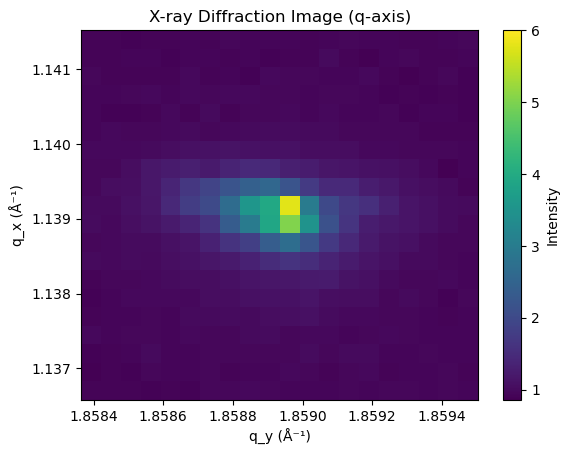

In [48]:
Omega = 13
Omg_rad=(math.pi/180)*Omega
Q_map = []
Q = []
rx = (qx - center_x) * pixel_size
ry = (qy - center_y) * pixel_size
Qx = (2 * np.pi / wavelength) * np.sin(Chi_rad)*(np.sin(Theta_rad+ np.arctan(ry / detector_distance)))
Qz = (4 * np.pi / wavelength) * np.sin(Theta_rad + np.arctan(ry / detector_distance))*(np.sin(Chi_rad))
Qy = (2 * np.pi / wavelength) * (np.cos(Chi_rad + np.arctan(rx / detector_distance))*(np.sin(Theta_rad)) + np.sin(Omg_rad))
Qxy = np.sqrt((Qx)**2 + (Qy)**2)
Q_z = np.round(Qz, 4)
Q_xy = np.round(Qxy, 4)
Q = np.sqrt((Qx)**2 + (Qy)**2 + (Qz)**2)
Q_map.append(Q)
plt.pcolormesh(Qy, Qx, Int.mean(0), vmax = 6)
plt.xlabel("q_y (Å⁻¹)")
plt.ylabel("q_x (Å⁻¹)")
plt.title("X-ray Diffraction Image (q-axis)")
plt.colorbar(label="Intensity")
plt.show()

In [28]:
import numpy as np

# === Given parameters ===
a = b = 5.499   # Å
c = 25.798      # Å
wavelength = 1.1055  # Å
L0 = 1.5E10     # sample-to-detector distance
w = rx  # example pixel width coords
h = ry  # example pixel height coords

# Angles in degrees
omega_deg = 6.06
two_theta_deg = 43.70
chi_deg = 36
phi_deg = 5.0
azi_deg = 2.0

# === Convert angles to radians ===
omega = np.radians(omega_deg)
two_theta = np.radians(two_theta_deg)
chi = np.radians(chi_deg)
phi = np.radians(phi_deg)
azi = np.radians(azi_deg)

# === Step 1: Calculate q in lab frame ===
k_mag = 2 * np.pi / wavelength

# Incident beam along +z
k_i = np.array([0, 0, 1])[:, np.newaxis, np.newaxis]
#k_inc = np.array([0, -np.sin(omega), np.cos(omega)])[:, np.newaxis, np.newaxis]

# Exit beam in lab coordinates
#k_f = np.array([
    #np.sin(two_theta) * np.cos(azi),
    #np.sin(two_theta) * np.sin(azi),
    #np.cos(two_theta)
#]) 


# ----------------------------
# Scattered wavevector in lab frame
# ----------------------------
k_f = np.array([
    L0 * np.sin(two_theta)*np.cos(azi) + w,
    L0 * np.sin(two_theta)*np.sin(azi) + h,
    np.broadcast_to(L0 * np.cos(two_theta), w.shape) 
    ])

# Normalize scattered wavevector per pixel
det_k_f = np.linalg.norm(k_f, axis=0)
k_out = k_f / det_k_f  # shape (3, ny, nx)

# ----------------------------
# Scattering vector q in lab frame
# ----------------------------
del_k = (k_out - k_i) * k_mag

#q_lab = k_f - k_i

# === Step 2: Transform to crystal frame and get hkl ===
# Rotation matrices
c_om, s_om = np.cos(omega), np.sin(omega)
R_omega = np.array([
    [1, 0, 0],
    [0, c_om, -s_om],
    [0, s_om, c_om]
])

c_phi, s_phi = np.cos(phi), np.sin(phi)
R_phi = np.array([
    [c_phi, 0, s_phi],
    [0, 1, 0],
    [-s_phi, 0, c_phi]
])

c_chi, s_chi = np.cos(chi), np.sin(chi)
R_chi = np.array([
    [c_chi, -s_chi, 0],
    [s_chi,  c_chi, 0],
    [0, 0, 1]
])

# Total rotation: R_phi * R_chi * R_omega
R_total = R_phi @ R_chi @ R_omega

# q in crystal coordinates
q_crystal = np.tensordot(np.linalg.inv(R_total), del_k, axes=(1, 0))

# Reciprocal lattice constants
a_star = 2 * np.pi / a
c_star = 2 * np.pi / c

# Reciprocal lattice basis matrix
B = np.array([
    [a_star, 0, 0],
    [0, a_star, 0],
    [0, 0, c_star]
])

# Fractional hkl
hkl = np.tensordot(np.linalg.inv(B), q_crystal, axes=(1, 0))  # shape (3, ny, nx)

# ----------------------------
# Separate q components
# ----------------------------
qx = q_crystal[0]  # qx
qy = q_crystal[1]  # qy
qz = q_crystal[2]  # qz

h = hkl[0]
k = hkl[1]
l = hkl[2]

print("H shape:", h.shape)
print("K shape:", k.shape)
print("L shape:", l.shape)

H shape: (20, 20)
K shape: (20, 20)
L shape: (20, 20)


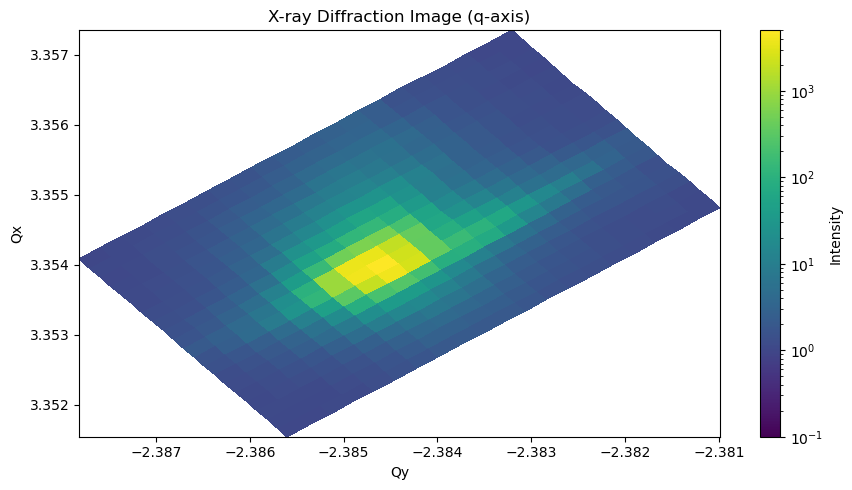

In [32]:
import matplotlib.pyplot as plt
qkl = np.sqrt((qy)**2 + (qz)**2)
#Q_z = np.round(Qz, 4)
q_KL = np.round(qkl, 5)
q_y = np.round(qy, 5)
#Q = np.sqrt((Qx)**2 + (Qy)**2 + (Qz)**2)
#Q_map.append(Q)
fig, ax = plt.subplots(figsize=(9, 5))
#mesh = ax.pcolormesh(q_y, qx, Int.mean(0), vmax=5, shading='auto')
mesh = ax.pcolormesh(
    q_y, qx, Int.mean(0),
    norm=LogNorm(vmin=1e-1, vmax=5000),  # adjust vmin to avoid log(0)
    shading='auto')

ax.set_xlabel("Qy")
ax.set_ylabel("Qx")
ax.set_title("X-ray Diffraction Image (q-axis)")

fig.colorbar(mesh, ax=ax, label="Intensity")
plt.tight_layout()
plt.show()

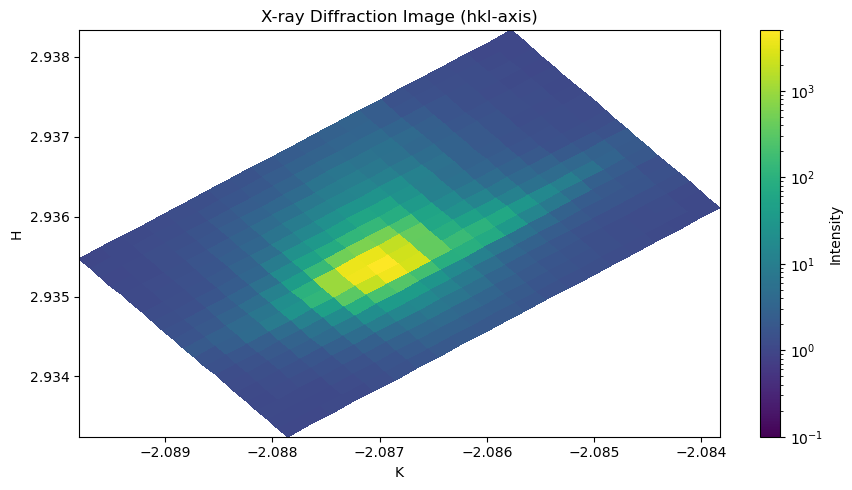

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
#mesh = ax.pcolormesh(k, h, Int.mean(0), vmax=5, shading='auto')
mesh = ax.pcolormesh(
    k, h, Int.mean(0),
    norm=LogNorm(vmin=1e-1, vmax=5000),  # adjust vmin to avoid log(0)
    shading='auto')

ax.set_xlabel("K")
ax.set_ylabel("H")
ax.set_title("X-ray Diffraction Image (hkl-axis)")

fig.colorbar(mesh, ax=ax, label="Intensity")
plt.tight_layout()
plt.show()

In [114]:
intensity = Int.mean(0)

# 2. Find the index of the maximum intensity
max_idx = (8, 8)

# 3. Get the corresponding Qx, Qy coordinates
max_h = h[max_idx]
max_k = k[max_idx]
#max_Qkl = Qkl[max_idx]
max_l = l[max_idx]
Qcen = np.sqrt((max_h)**2 + (max_k)**2 + (max_l)**2)
Q_cen = np.round(Qcen, 4)
Del_h = ((h - max_h)) 
Del_k = ((k - max_k))
Del_l = ((l - max_l))
Delhk = np.sqrt((h - max_h)**2 + (k - max_k)**2)
Delhkl = np.sqrt((h - max_h)**2 + (k - max_k)**2 + (l - max_l)**2)
Del_hk = np.round(Delhk , 5)
Del_hkl = np.round(Delhkl , 5)

print(f"Max intensity: {intensity[max_idx]:.3f} at H={max_h:.3f}, K={max_k:.3f}")

Max intensity: 5145.110 at H=2.935, K=-2.087


In [115]:
np.max(np.abs(Del_hkl))

0.0073

In [117]:
num_hkl_rings = 13 # Number of q-rings to create
hkl_min = np.min(Del_hkl)
hkl_max = np.max(Del_hkl)
#Q_min = np.round(Qmin, 2)
#Q_max = np.round(Qmax, 2)

hkl_step = (hkl_max - hkl_min) / num_hkl_rings
#Q_step = np.round(Qstep, 3)

hkl_ring_masks = []
for i in range(num_hkl_rings):
    hkl_start = hkl_min + i * hkl_step
    hkl_end = hkl_start + hkl_step
    mask = (Del_hkl >= hkl_start) & (Del_hkl < hkl_end)
    hkl_ring_masks.append(mask)

In [118]:
hkl_start

0.006738461538461539

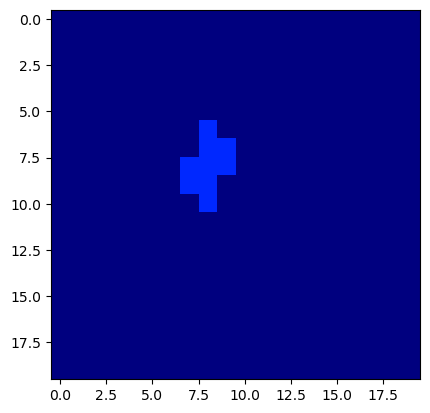

In [119]:
plt.imshow(hkl_ring_masks[0], cmap='jet', vmax=6)  # Plot the base image

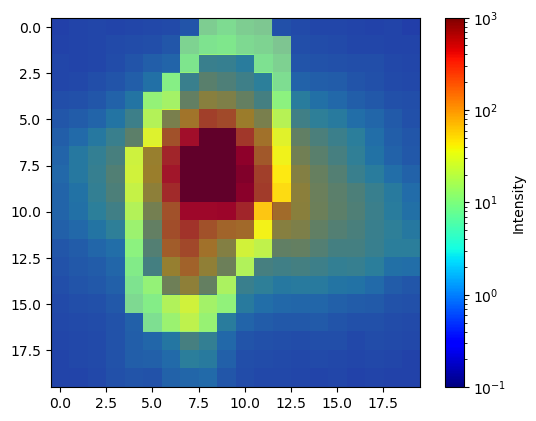

In [139]:
Img = np.nanmean(Int, axis = 0)
#plt.imshow(Img, cmap='jet', vmax=5)  # Plot the base image
plt.imshow(Img, cmap='jet', norm=LogNorm(vmin=1e-1, vmax=1000))
plt.colorbar(label="Intensity")
#plt.show()
#for i, mask in enumerate(Q_ring_masks[1]):
#plt.contour(hkl_ring_masks[5], levels= 0, colors= 'white') # Overlay the mask
plt.pcolormesh(px, py, hkl_ring_masks[3], cmap='viridis', alpha=0.5)
#plt.axis('off')  # Hide axes
plt.show()

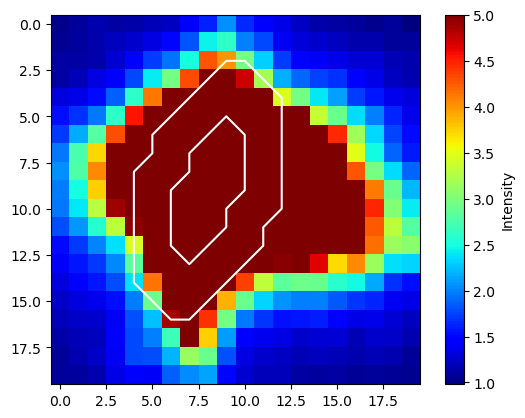

In [92]:
Img = np.nanmean(Int, axis = 0)
plt.imshow(Img, cmap='jet', vmax=5)  # Plot the base image
plt.colorbar(label="Intensity")
#for i, mask in enumerate(Q_ring_masks[1]):
plt.contour(hkl_ring_masks[2], levels= 0, colors= 'white') # Overlay the mask
#plt.pcolormesh(qx, qy, hkl_ring_masks[1], cmap='grey', alpha=0.5)
#plt.axis('off')  # Hide axes
plt.show()

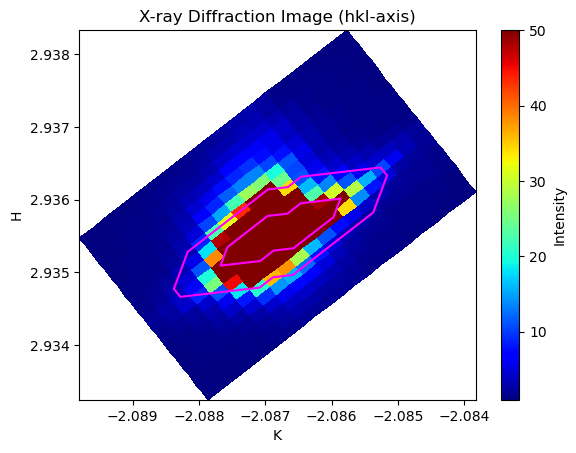

In [93]:
plt.pcolormesh(k, h, Int.mean(0), cmap='jet', vmax = 50)
plt.xlabel("K")
plt.ylabel("H")
plt.colorbar(label="Intensity")
plt.title("X-ray Diffraction Image (hkl-axis)")
#plt.imshow(Q_ring_masks[3], cmap='viridis', alpha=0.4)


# Set x- and y- range (adjust values as needed)
#plt.xlim(-2.042, -2.022)   # x-axis range for K
#plt.ylim(1.9625, 1.9825)   # y-axis range for H

#levels = np.arange(0, 7, 1)  # Define your desired contour levels
#colors = ['magenta', 'green', 'purple', 'orange', 'cyan', 'lime', 'white', 'gray']

plt.contour(k, h, hkl_ring_masks[2], levels= 0, colors= 'magenta')
#plt.colorbar(label="Intensity")
plt.show()

/tmp/ipykernel_1177015/31863664.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


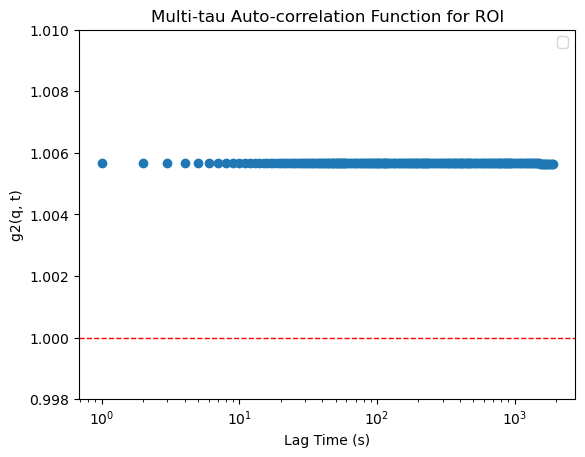

In [137]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt

# --- Define parameters for the multi-tau algorithm ---
num_levels = 6 # Number of multi-tau levels
num_bufs = 60 # Number of buffers to use at each level

#img_stack = Iframes[:].copy()
#img_stack = Int.copy() -Int.mean(0) -  np.min(Int.copy() -Int.mean(0))
img_stack = Int.copy() -Iframes_avg_sg - np.min(Int.copy() -Iframes_avg_sg)
#img_stack = Iframes.copy() -Iframes_avg_gf -  np.min(Iframes.copy() -Iframes_avg_gf)


#create 2D boolean array 'labeled_roi_array' where ROI box is 1
labeled_roi_array = np.zeros(img_stack.shape[1:3], dtype = np.int64)
#set ROI = 1
labeled_roi_array[hkl_ring_masks[3]] = 1

# --- Calculate the multi-tau auto-correlation ---
g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,  # Your labeled ROI array
    img_stack[0:]  # Your image stack (as an iterable)
)

plt.semilogx(lag_steps[1:],(g2[1:]),'o',)
plt.xlabel('Lag Time (s)')
plt.ylabel('g2(q, t)')
plt.title('Multi-tau Auto-correlation Function for ROI')
plt.ylim(0.998,1.01)
plt.axhline(y=1, color='r', linestyle='--', linewidth=1)
plt.legend()
plt.show()
# --- Explanation of parameters ---
# num_levels: Controls the number of levels in the multi-tau algorithm, impacting the maximum lag time computed.
# num_bufs:  Controls the number of frames buffered at each level, impacting the number of lag times computed within each level.
# labeled_roi_array:  Defines the regions of interest (ROIs) on your detector images. Each pixel belonging to an ROI is assigned a unique label (an integer).
# img_stack:  An iterable containing your image data, typically a sequence of frames obtained from your XPCS experiment.

In [264]:
g2_q = g2[1:].reshape(-1)

Fitted Parameters:
beta: 0.009 ± 0.001
tau_c: 500.000 ± 51.890
alpha: 2.113 ± 0.516
baseline: 1.068 ± 0.001


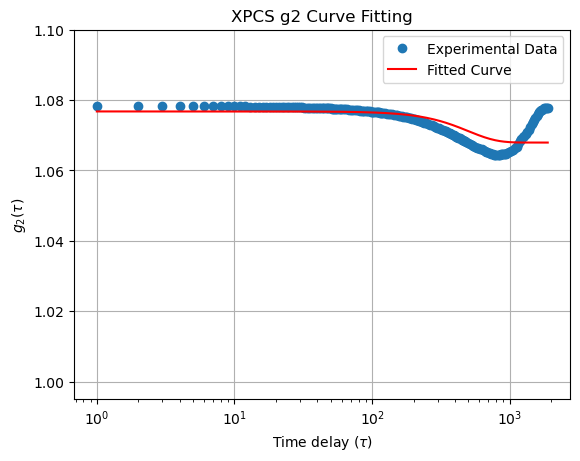

In [265]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the model function for the g2 curve
# A common model for XPCS is the stretched exponential decay
# g2(tau) = 1 + beta * exp(-(tau/tau_c)^alpha)
def g2_stretched_exponential(tau, beta, tau_c, alpha, baseline):
  """
  Stretched exponential fitting function for XPCS g2 curves.

  Args:
    tau: The time delay (independent variable).
    beta: The amplitude (contrast).
    tau_c: The characteristic decay time.
    alpha: The stretching exponent.
    baseline: The baseline value of the correlation function (ideally 1).

  Returns:
    The calculated g2 value at time delay tau.
  """
  return baseline + beta * np.exp(-(tau/tau_c)**alpha)

# Assuming you have your experimental data in arrays:
# xdata: time delays (tau)
# ydata: g2 values

# Example data (replace with your actual data)
xdata = lag_steps[1:]
ydata =  g2_q

# Initial guess for the fitting parameters
# It's important to provide good initial guesses for the fit to converge well
p0 = [0.010, 1000, 1.0, 0.95] # [beta, tau_c, alpha, baseline]

# Fixing a Parameter: Example - fixing the baseline to 1.0
# You can use the 'bounds' argument in curve_fit to constrain parameters.
# In this case, set the lower and upper bound for the baseline parameter to 1.0
# The order of the bounds should correspond to the order of the parameters in the function definition.
lower_bounds = [0.002, 500, 0.2, 0.9] # Bounds for [beta, tau_c, alpha, baseline]
upper_bounds = [0.18, 1320, 2.5, 1.5]

# Perform the curve fit
# Pass the function, data, initial guess, and bounds to curve_fit.
popt, pcov = curve_fit(g2_stretched_exponential, xdata, ydata, p0=p0, bounds=(lower_bounds, upper_bounds))

# Extract the fitted parameters and their uncertainties
fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline = popt
perr = np.sqrt(np.diag(pcov)) # Diagonal of covariance matrix gives parameter variances

print("Fitted Parameters:")
print(f"beta: {fitted_beta:.3f} ± {perr[0]:.3f}")
print(f"tau_c: {fitted_tau_c:.3f} ± {perr[1]:.3f}")
print(f"alpha: {fitted_alpha:.3f} ± {perr[2]:.3f}")
print(f"baseline: {fitted_baseline:.3f} ± {perr[3]:.3f}") # Uncertainty will be 0 as it was fixed

# Generate data for the fitted curve for plotting
tau_fit = np.linspace(min(xdata), max(xdata), 100) # Creates a smooth curve
g2_fit = g2_stretched_exponential(tau_fit, *popt) # Calculate g2 values using fitted parameters

# Calculate the fitted curve using the optimized parameters
yfit = g2_stretched_exponential(xdata, fitted_beta, fitted_tau_c, fitted_alpha, fitted_baseline)

# Plot the data and the fitted curve
plt.figure()
plt.semilogx(xdata, ydata, 'o', label='Experimental Data')
plt.semilogx(xdata, yfit, 'r-', label='Fitted Curve')
#plt.plot(xdata, ydata, 'o', label='Experimental Data')
#plt.plot(xdata, yfit, 'r-', label='Fitted Curve')
plt.xlabel('Time delay ($\\tau$)')
plt.ylabel('$g_2(\\tau)$')
plt.title('XPCS g2 Curve Fitting')
plt.ylim(0.995,1.1)
plt.legend()
plt.grid(True)
plt.show()

In [47]:
combined_data = np.column_stack((lag_steps[1:],(g2[1:])))
# Save to a text file (e.g., space-delimited)
np.savetxt('Sr2IrO4_205K_Q0-ring.txt', combined_data, fmt='%.7f', delimiter='\t', header='X_Value\tY_Value')

In [266]:
Qy

-0.623682506685418

In [429]:
intensity = Int.mean(0)

# 2. Find the index of the maximum intensity
max_idx = np.unravel_index(np.argmax(intensity), intensity.shape)

# 3. Get the corresponding Qx, Qy coordinates
max_Qx = Qx[max_idx]
max_Qy = Qy[max_idx]
max_Qxy = Qxy[max_idx]
max_Qz = Qz[max_idx]
Qcen = np.sqrt((max_Qx)**2 + (max_Qy)**2)
Q_cen = np.round(Qcen, 4)
Del_Qx = ((Qx - max_Qx)) 
Del_Qy = ((Qy - max_Qy))
DelQ = np.sqrt((Qx - max_Qx)**2 + (Qy - max_Qy)**2)
Del_Q = np.round(DelQ , 5)

print(f"Max intensity: {intensity[max_idx]:.3f} at Qx={max_Qx:.3f}, Qy={max_Qy:.3f}")

Max intensity: 5.765 at Qx=1.140, Qy=1.861


In [433]:
np.max(Del_Q)

0.00253

In [430]:
num_Q_rings = 8 # Number of q-rings to create
Q_min = np.min(Del_Q)
Q_max = np.max(Del_Q)
#Q_min = np.round(Qmin, 2)
#Q_max = np.round(Qmax, 2)

Q_step = (Q_max - Q_min) / num_Q_rings
#Q_step = np.round(Qstep, 3)

Q_ring_masks = []
for i in range(num_Q_rings):
    Q_start = Q_min + i * Q_step
    Q_end = Q_start + Q_step
    mask = (Del_Q >= Q_start) & (Del_Q < Q_end)
    Q_ring_masks.append(mask)

In [59]:
Q_ring_masks

[array([[False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False],
        [False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False],
        [False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False],
        [False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False],
        [False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False],
        [False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, 

In [113]:
#plt.contour(Q_ring_masks[3], levels= 0, colors= 'black')

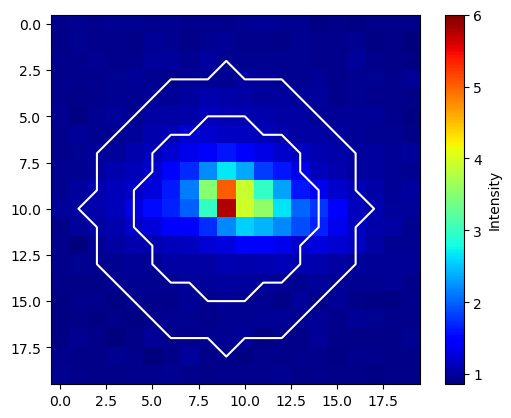

In [132]:
Img = np.nanmean(Int, axis = 0)
plt.imshow(Img, cmap='jet', vmax=6)  # Plot the base image
plt.colorbar(label="Intensity")
#for i, mask in enumerate(Q_ring_masks[1]):
plt.contour(Q_ring_masks[3], levels= 0, colors= 'white') # Overlay the mask
#plt.pcolormesh(Qxy, Qz, Q_ring_masks[3], cmap='viridis', alpha=0.8)
#plt.axis('off')  # Hide axes
plt.show()

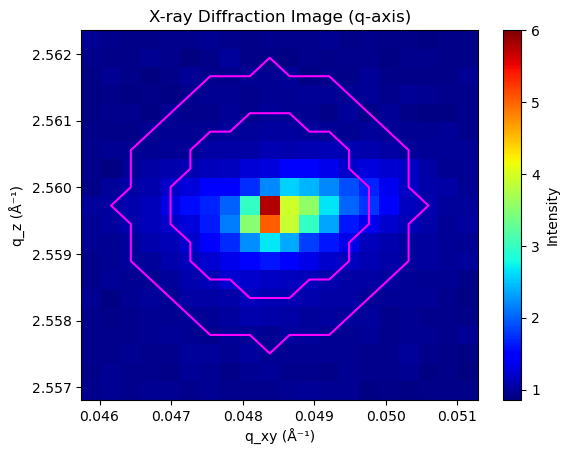

In [131]:
plt.pcolormesh(Qxy, Qz, Int.mean(0), cmap='jet', vmax = 6)
plt.xlabel("q_xy (Å⁻¹)")
plt.ylabel("q_z (Å⁻¹)")
plt.colorbar(label="Intensity")
plt.title("X-ray Diffraction Image (q-axis)")
#plt.imshow(Q_ring_masks[3], cmap='viridis', alpha=0.4)

#levels = np.arange(0, 7, 1)  # Define your desired contour levels
#colors = ['magenta', 'green', 'purple', 'orange', 'cyan', 'lime', 'white', 'gray']

plt.contour(Qxy, Qz, Q_ring_masks[3], levels= 0, colors= 'magenta')
#plt.colorbar(label="Intensity")
plt.show()

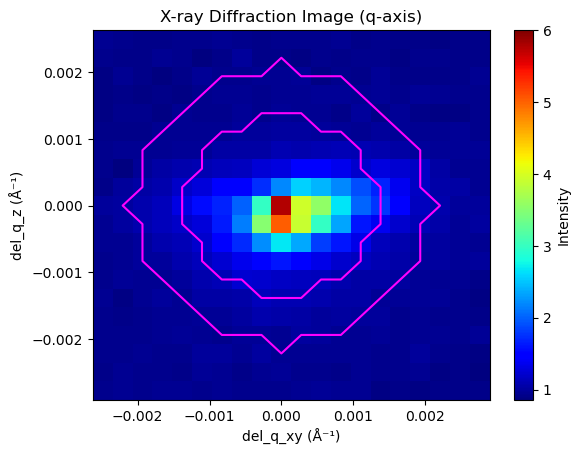

In [121]:
plt.pcolormesh(Del_Qxy, Del_Qz, Int.mean(0), cmap='jet', vmax = 6)
plt.xlabel("del_q_xy (Å⁻¹)")
plt.ylabel("del_q_z (Å⁻¹)")
plt.colorbar(label="Intensity")
plt.title("X-ray Diffraction Image (q-axis)")
#plt.imshow(Q_ring_masks[3], cmap='viridis', alpha=0.4)

#levels = np.arange(0, 7, 1)  # Define your desired contour levels
#colors = ['magenta', 'green', 'purple', 'orange', 'cyan', 'lime', 'white', 'gray']

plt.contour(Del_Qxy, Del_Qz, Q_ring_masks[3], levels= 0, colors= 'magenta')
#plt.colorbar(label="Intensity")
plt.show()

In [29]:
import numpy as np

# ----------------------------
# Input parameters
# ----------------------------
wavelength = 1.1055   # Å
omega_deg = 13.0      # degrees
two_theta_deg = 26.0  # degrees
L0 = 1.5E10           # sample-to-detector distance
w = rx  # example pixel width coords
h = ry  # example pixel height coords

# ----------------------------
# Convert angles to radians
# ----------------------------
omega = np.radians(omega_deg)
two_theta = np.radians(two_theta_deg)

# ----------------------------
# Incident wavevector (unit vector) in lab frame
# Shape: (3,1,1) for broadcasting with pixel arrays
# ----------------------------
k_i = np.array([0, -np.sin(omega), np.cos(omega)])[:, np.newaxis, np.newaxis]

# ----------------------------
# Scattered wavevector in lab frame
# ----------------------------
k_f = np.array([
    w,
    L0 * np.sin(two_theta/2) + h,
    np.broadcast_to(L0 * np.cos(two_theta/2), w.shape) 
])

# Normalize scattered wavevector per pixel
det_k_f = np.linalg.norm(k_f, axis=0)
k_out = k_f / det_k_f  # shape (3, ny, nx)

# ----------------------------
# Scattering vector q in lab frame
# ----------------------------
del_k = (k_out - k_i) * (2 * np.pi / wavelength)

# ----------------------------
# Separate q components
# ----------------------------
qx = del_k[0]  # shape (ny, nx)
qy = del_k[1]
qz = del_k[2]

print("qx shape:", qx.shape)
print("qy shape:", qy.shape)
print("qz shape:", qz.shape)


qx shape: (20, 20)
qy shape: (20, 20)
qz shape: (20, 20)


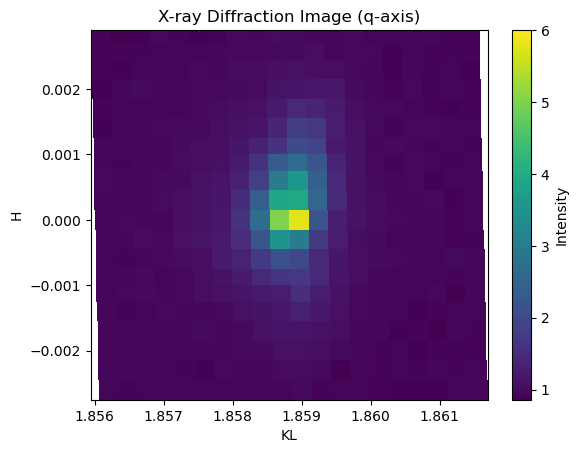

In [30]:
qkl = np.sqrt((qy)**2 + (qz)**2)
#Q_z = np.round(Qz, 4)
q_KL = np.round(Qkl, 5)
q_H = np.round(qx, 4)
#Q = np.sqrt((Qx)**2 + (Qy)**2 + (Qz)**2)
#Q_map.append(Q)
plt.pcolormesh(q_KL, q_H, Int.mean(0), vmax = 6)
plt.xlabel("KL")
plt.ylabel("H")
plt.title("X-ray Diffraction Image (q-axis)")
plt.colorbar(label="Intensity")
plt.show()

In [63]:
import numpy as np

# ----------------------------
# Input parameters
# ----------------------------
wavelength = 1.1055   # Å
omega_deg = 6.35      # degrees
two_theta_deg = 26.0  # degrees
chi_deg = 1.12  # degrees
L0 = 1.5E10           # sample-to-detector distance
w = rx  # example pixel width coords
h = ry  # example pixel height coords

# ----------------------------
# Convert angles to radians
# ----------------------------
omega = np.radians(omega_deg)
two_theta = np.radians(two_theta_deg)
chi = np.radians(chi_deg)

# ----------------------------
# Incident wavevector (unit vector) in lab frame
# Shape: (3,1,1) for broadcasting with pixel arrays
# ----------------------------
k_inc = np.array([0, -np.sin(omega), np.cos(omega)])[:, np.newaxis, np.newaxis]

# ----------------------------
# Scattered wavevector in lab frame
# ----------------------------
k_scat = np.array([
    L0 * np.sin(two_theta/2)*np.sin(chi) + w,
    L0 * np.sin(two_theta/2)*np.cos(chi) + h,
    np.broadcast_to(L0 * np.cos(two_theta/2), w.shape) 
])

# Normalize scattered wavevector per pixel
norm_k_scat = np.linalg.norm(k_scat, axis=0)
k_out = k_scat / norm_k_scat  # shape (3, ny, nx)

# ----------------------------
# Scattering vector q in lab frame
# ----------------------------
del_k = (k_out - k_inc) * (2 * np.pi / wavelength)

# ----------------------------
# Separate q components
# ----------------------------
h = del_k[0]  # qx
k = del_k[1]  # qy
l = del_k[2]  # qz

print("H shape:", h.shape)
print("K shape:", k.shape)
print("L shape:", l.shape)


H shape: (20, 20)
K shape: (20, 20)
L shape: (20, 20)


/tmp/ipykernel_2842748/643179801.py:7: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(Q_KL, Q_H, Int.mean(0), vmax = 6)


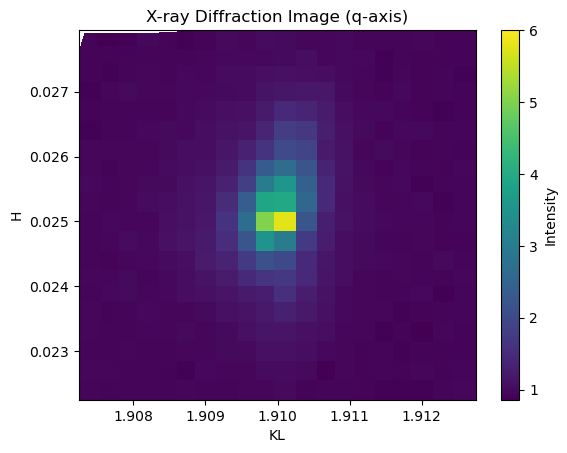

In [64]:
Qkl = np.sqrt((k)**2 + (l)**2)
#Q_z = np.round(Qz, 4)
Q_KL = np.round(Qkl, 4)
Q_H = np.round(h, 4)
#Q = np.sqrt((Qx)**2 + (Qy)**2 + (Qz)**2)
#Q_map.append(Q)
plt.pcolormesh(Q_KL, Q_H, Int.mean(0), vmax = 6)
plt.xlabel("KL")
plt.ylabel("H")
plt.title("X-ray Diffraction Image (q-axis)")
plt.colorbar(label="Intensity")
plt.show()

In [45]:
intensity = Int.mean(0)

# 2. Find the index of the maximum intensity
max_idx = np.unravel_index(np.argmax(intensity), intensity.shape)

# 3. Get the corresponding Qx, Qy coordinates
max_h = h[max_idx]
max_k = k[max_idx]
max_Qkl = Qkl[max_idx]
max_l = l[max_idx]
Qcen = np.sqrt((max_h)**2 + (max_k)**2 + (max_l)**2)
Q_cen = np.round(Qcen, 4)
Del_h = ((h - max_h)) 
Del_k = ((k - max_k))
Del_l = ((l - max_l))
Delhkl = np.sqrt((h - max_h)**2 + (k - max_k)**2 + (l - max_l)**2)
Del_hkl = np.round(Delhkl , 5)

print(f"Max intensity: {intensity[max_idx]:.3f} at H={max_h:.3f}, K={max_k:.3f}")

Max intensity: 5.765 at H=1.134, K=1.869


In [48]:
np.max(Del_hkl)

0.00401

In [49]:
num_hkl_rings = 8 # Number of q-rings to create
hkl_min = np.min(Del_hkl)
hkl_max = np.max(Del_hkl)
#Q_min = np.round(Qmin, 2)
#Q_max = np.round(Qmax, 2)

hkl_step = (hkl_max - hkl_min) / num_hkl_rings
#Q_step = np.round(Qstep, 3)

hkl_ring_masks = []
for i in range(num_hkl_rings):
    hkl_start = hkl_min + i * hkl_step
    hkl_end = hkl_start + hkl_step
    mask = (Del_hkl >= hkl_start) & (Del_hkl < hkl_end)
    hkl_ring_masks.append(mask)

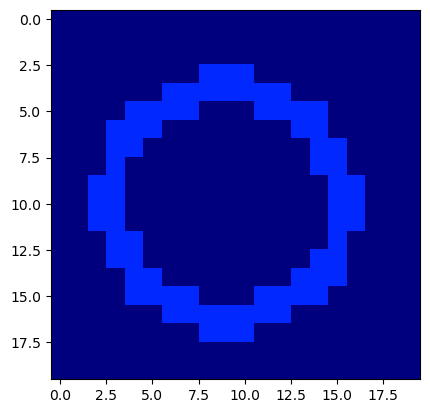

In [60]:
plt.imshow(hkl_ring_masks[3], cmap='jet', vmax=6)  # Plot the base image

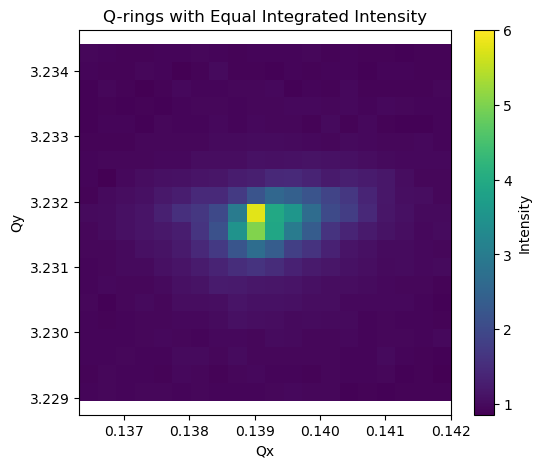

In [128]:
intensity = Int.mean(0)
q = np.sqrt(Qx**2 + Qy**2)

# Flatten and sort by q:
q_flat = q.ravel()
int_flat = intensity.ravel()
sorted_indices = np.argsort(q_flat)
q_sorted = q_flat[sorted_indices]
int_sorted = int_flat[sorted_indices]

# Compute cumulative intensity:
cum_int = np.cumsum(int_sorted)

# Define number of rings:
num_rings = 6
total_intensity = cum_int[-1]
int_bins = np.linspace(0, total_intensity, num_rings + 1)

# Find q boundaries for equal intensity bins:
q_edges = np.interp(int_bins, cum_int, q_sorted)

# Plot:
plt.figure(figsize=(6,5))
mesh = plt.pcolormesh(Qx, Qy, intensity, vmax=6)
plt.colorbar(mesh, label='Intensity')
plt.xlabel('Qx')
plt.ylabel('Qy')

plt.title('Q-rings with Equal Integrated Intensity')
plt.axis('equal')
plt.show()

In [109]:
Q_cen

3.2348

In [93]:
np.min(Q_map)

3.231983765429523

In [117]:
num_Q_rings = 8 # Number of q-rings to create
Q_min = Q_cen
#Qmax = np.max(Q_map)
#Q_min = np.round(Qmin, 2)
#Q_max = np.round(Qmax, 2)

Q_step = 0.002
#Q_step = np.round(Qstep, 3)

Q_ring_masks = []
for i in range(num_Q_rings):
    Q_start = Q_min + i * Q_step
    Q_end = Q_start + Q_step
    mask = (Q_map >= Q_start) & (Q_map < Q_end)
    Q_ring_masks.append(mask)

In [101]:
#num_Q_rings = 8 # Number of q-rings to create
#Qmin =np.min(Q_map)
#Qmax = np.max(Q_map)
#Q_min = np.round(Qmin, 2)
#Q_max = np.round(Qmax, 2)

#Qstep = (Q_max - Q_min) / num_Q_rings
#Q_step = np.round(Qstep, 3)

#Q_ring_masks = []
#for i in range(num_Q_rings):
    #Q_start = Q_min + i * Q_step
    #Q_end = Q_start + Q_step
    #mask = (Q_map >= Q_start) & (Q_map < Q_end)
    #Q_ring_masks.append(mask)

In [118]:
Q_ring_masks

[array([[[False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,
          False, False],
         [False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,
          False, False],
         [False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,
          False, False],
         [False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,
          False, False],
         [False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,
          False, False],
         [False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False,

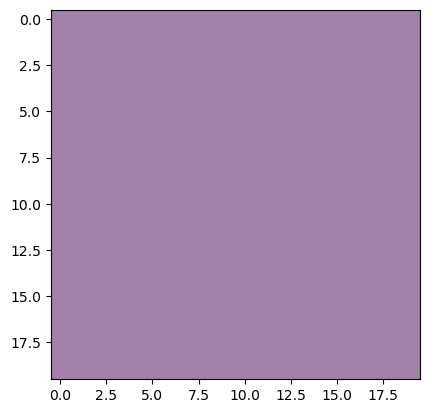

In [120]:
#Q_ring_masks_2d =  Q_ring_masks.squeeze(axis=0) 
plt.imshow( Q_ring_masks[2][0], cmap='viridis', alpha=0.5) 

TypeError: Invalid shape (1, 20, 20) for image data

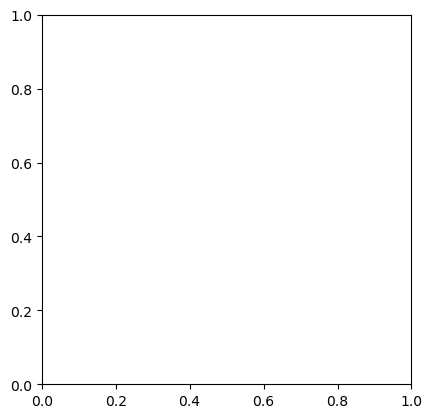

In [76]:
plt.figure()
for i, mask in enumerate(Q_ring_masks):
    plt.imshow(mask, cmap='viridis', alpha=0.5) # You can choose different colors/transparency
   # plt.text(center_x, center_y, f'Q-ring {i+1}', color='black') # Add labels if needed
plt.title('Equal Q-rings ROI')
plt.show()

In [264]:
# Example: Extract the average intensity for each q-ring
Img = np.nanmean(Int, axis = 0)
average_intensities = []
for mask in Q_ring_masks:
    roi_pixels = Img[mask] # Assuming Img holds your 2D scattering data
    average_intensity = np.mean(roi_pixels)
    average_intensities.append(average_intensity)

In [265]:
average_intensities

[3.5098987876765655,
 1.8451487201487204,
 1.2187090937090939,
 1.0386553219886554,
 0.9657048352700528,
 0.9385502523800396,
 0.9257815507815509,
 0.9116616616616616]

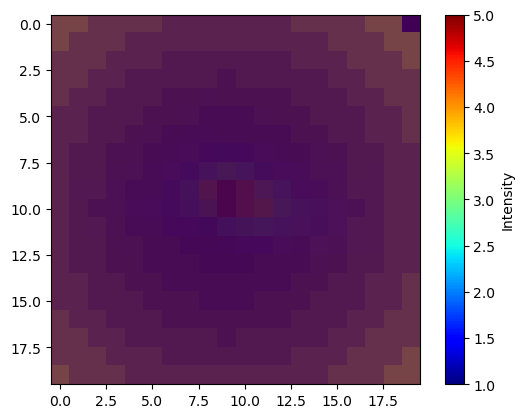

In [316]:
plt.imshow(Img, cmap='jet', vmin = 1, vmax=5)  # Plot the base image
plt.colorbar(label="Intensity")
for i, mask in enumerate(Q_ring_masks):
    plt.imshow(mask, cmap='viridis', alpha=0.3) # Overlay the mask
#plt.axis('off')  # Hide axes
plt.show()

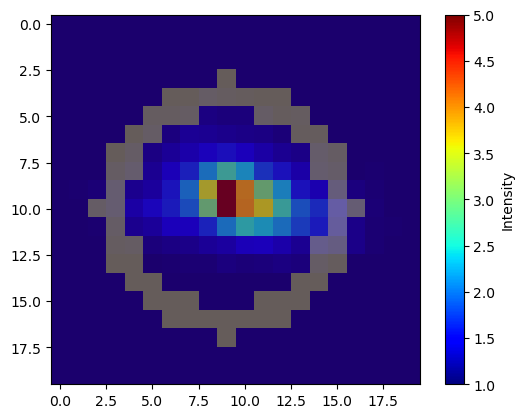

In [282]:
plt.imshow(Img, cmap='jet', vmin = 1, vmax=5)  # Plot the base image
plt.colorbar(label="Intensity")
#for i, mask in enumerate(Q_ring_masks[1]):
plt.imshow(Q_ring_masks[3], cmap='viridis', alpha=0.4) # Overlay the mask
#plt.axis('off')  # Hide axes
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


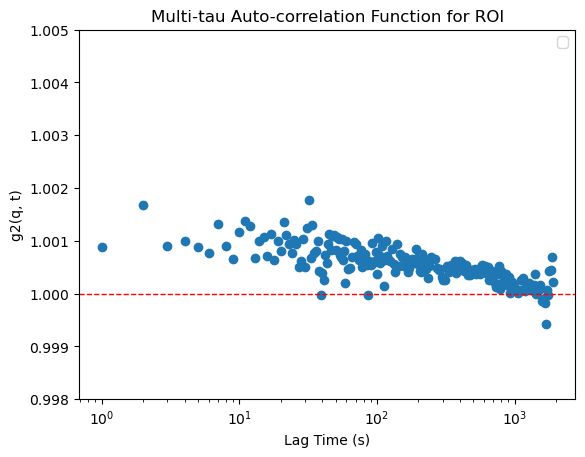

In [318]:
import numpy as np
from skbeam.core import correlation
import matplotlib.pyplot as plt

# --- Define parameters for the multi-tau algorithm ---
num_levels = 6 # Number of multi-tau levels
num_bufs = 60 # Number of buffers to use at each level

#img_stack = Iframes[:].copy()
#img_stack = Iframes.copy() -Iframes.mean(0) -  np.min(Iframes.copy() -Iframes.mean(0))
xpcs_stack = Int.copy() -Iframes_avg_sg - np.min(Int.copy() -Iframes_avg_sg)
#img_stack = Iframes.copy() -Iframes_avg_gf -  np.min(Iframes.copy() -Iframes_avg_gf)


#create 2D boolean array 'labeled_roi_array' where ROI box is 1
labeled_roi_array = np.zeros(xpcs_stack.shape[1:3], dtype = np.int64)
#set ROI = 1
labeled_roi_array[Q_ring_masks[1]] = 1

# --- Calculate the multi-tau auto-correlation ---
g2, lag_steps = correlation.multi_tau_auto_corr(
    num_levels,
    num_bufs,
    labeled_roi_array,  # Your labeled ROI array
    xpcs_stack[0:]  # Your image stack (as an iterable)
)

plt.semilogx(lag_steps[1:],(g2[1:]),'o',)
plt.xlabel('Lag Time (s)')
plt.ylabel('g2(q, t)')
plt.title('Multi-tau Auto-correlation Function for ROI')
plt.ylim(0.998,1.005)
plt.axhline(y=1, color='r', linestyle='--', linewidth=1)
plt.legend()
plt.show()
# --- Explanation of parameters ---
# num_levels: Controls the number of levels in the multi-tau algorithm, impacting the maximum lag time computed.
# num_bufs:  Controls the number of frames buffered at each level, impacting the number of lag times computed within each level.
# labeled_roi_array:  Defines the regions of interest (ROIs) on your detector images. Each pixel belonging to an ROI is assigned a unique label (an integer).
# img_stack:  An iterable containing your image data, typically a sequence of frames obtained from your XPCS experiment.

In [301]:
labeled_roi_array[Q_ring_masks[2]] = 1

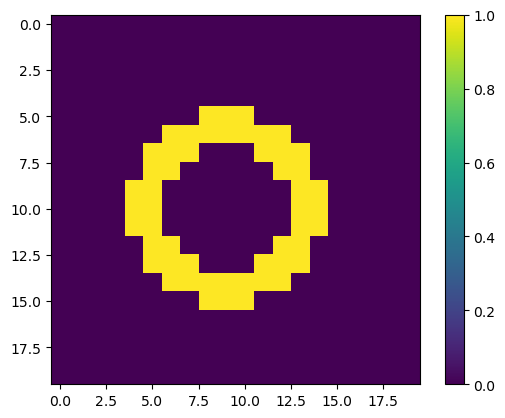

In [283]:
plt.imshow(labeled_roi_array)
plt.colorbar()

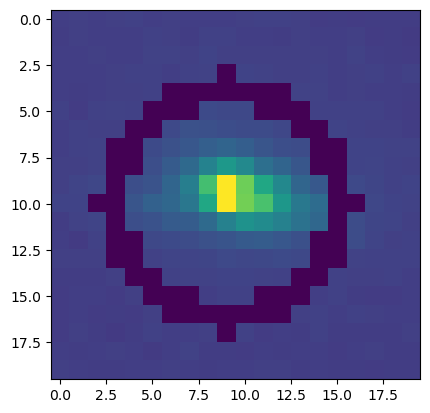

In [300]:
#plot ROI region
Int_mask = Int.mean(0)
Int_mask[Q_ring_masks[3]]=0
plt.figure()
plt.imshow(Int_mask,vmax = 5, vmin = 0)
#plt.title(200K, fontsize = 20)

In [53]:
Int.shape[1]

20

In [ ]:
#plt.plot(average_intensities, 'o')